# Customer Behaviour Analysis

# Objective
In this case study, you will be working on E-commerce Customer Behavior Analysis using Apache Spark, a powerful distributed computing framework designed for big data processing. This assignment aims to give you hands-on experience in analyzing large-scale e-commerce datasets using PySpark. You will apply techniques learned in data analytics to clean, transform, and explore customer behavior data, drawing meaningful insights to support business decision-making. Apart from understanding how big data tools can optimize performance on a single machine and across clusters, you will develop a structured approach to analyzing customer segmentation, purchase patterns, and behavioral trends.

# Business Value
E-commerce businesses operate in a highly competitive market where understanding customer behavior is critical to driving growth and retention. To stay ahead, companies must leverage data-driven insights to optimize marketing strategies, personalize customer experiences, and improve product offerings. In this assignment, you will analyze e-commerce transaction data to uncover patterns in purchasing behavior, customer preferences, and sales performance. With Apache Spark's ability to handle large datasets efficiently, businesses can process vast amounts of customer interactions in real-time, helping them make faster and more informed decisions.
As an analyst at an e-commerce company, your task is to examine historical transaction records and customer survey data to derive actionable insights that can drive business growth. Your analysis will help identify high-value customers, segment users based on behavior, and uncover trends in product demand and customer engagement. By leveraging big data analytics, businesses can enhance customer satisfaction, improve retention rates, and maximize revenue opportunities.


# Assignment Tasks
1. Data Preparation
2. Data Cleaning
3. Exploratory Data Analysis
4. Customer Segmentation (RFM Analysis) and Business Insights
5. Evaluation and Conclusion


# Dataset Overview
The dataset can be accessed the following [link](https://drive.google.com/drive/folders/1mBgC5tvZrh1bIBvpXVP_j-au5LFUAwOZ?usp=sharing).

The dataset used in this analysis comprises longitudinal purchase records from 5,027 Amazon.com users in the United States, spanning 2018 to 2022.

It is structured into three CSV files (amazon-purchases.csv, survey.csv, and fields.csv) that capture transactional data, demographic profiles, and survey responses.

Collected with informed consent, the dataset enables analysis of customer behavior, product preferences, and demographic trends.

**NOTE**: Personal identifiers (PII) were removed to ensure privacy, and all data were preprocessed by users before submission.

`Data Dictionary:`

| **Attribute**          | **Description** |
|------------------------|----------------|
| **Order Dates**        | The specific dates when orders were placed, enabling chronological analysis of sales trends. |
| **Title** |The name of the product purchased. |
|**Category** | The classification or group to which the product belongs, facilitating category-wise analysis. |
| **Pricing** | The cost per unit of each product, essential for revenue calculations and pricing strategy assessments. |
| **Quantities** | The number of units of each product ordered in a transaction, aiding in inventory and demand analysis. |
| **Shipping States**    | The states to which products were shipped, useful for geographical sales distribution analysis. |
| **Survey ResponseID**  | A unique identifier linking purchases to customer survey responses, enabling correlation between purchasing behavior and customer feedback. |



# Loading the Datasets

In [ ]:
## Installing the libraries if required
# !pip install --quiet pyspark==3.5.4 datasets==3.3.2 pandas==2.2.2 matplotlib==3.10.0 seaborn==0.13.2 numpy==1.26.4 tqdm==4.67.1

In [49]:
try:
    spark.stop()
except:
    pass


In [1]:
# Import necessary libraries
from pyspark.sql import SparkSession

# Initialise Spark session
spark = SparkSession.builder \
    .appName("Customer Behavior Analysis") \
    .config("spark.driver.memory", "6g") \
    .config("spark.executor.memory", "6g") \
    .getOrCreate()

25/07/10 19:56:46 WARN Utils: Your hostname, Adityas-MacBook-Air.local resolves to a loopback address: 127.0.0.1; using 192.168.1.101 instead (on interface en0)
25/07/10 19:56:46 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/07/10 19:56:46 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:


# Load the paths to the datasets/csv files
amazon_purchases_path = "/Users/adityavardhan/Desktop/amazon-purchases.csv"
survey_path = "/Users/adityavardhan/Desktop/survey.csv"
fields_path ="/Users/adityavardhan/Desktop/fields.csv"

# Load datasets into PySpark DataFrames
amazon_purchases = spark.read.csv(amazon_purchases_path, header=True, inferSchema=True)
survey = spark.read.csv(survey_path, header=True, inferSchema=True)
fields = spark.read.csv(fields_path, header=True, inferSchema=True)

# Merge the datasets
merged_data = amazon_purchases.join(survey, on="Survey ResponseID", how="left")

# Display the merged data
merged_data.show(5, truncate=False)

25/07/10 19:56:50 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-----------------+----------+-----------------------+--------+----------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+------------------------+-------------+-------------+----------------+-------------------------+-----------------+-----------------+--------------+-----------------------+-------------+--------------------+--------------------+---------------------------+--------------------------+-------------------------+-----------------------+-------------------+---------------------+--------------+-------------------------------+---------------------------------------+---------------+------------+------------------+
|Survey ResponseID|Order Date|Purchase Price Per Unit|Quantity|Shipping Address State|Title                                                                                                                             

#1. Data Preparation

Before analysis, the data needs to be prepared to ensure consistency and efficiency.
- Check for data consistency and ensure all columns are correctly formatted.
- Structure and prepare the dataset for further processing, ensuring that relevant features are retained


In [5]:
from pyspark.sql.functions import col, count, when, to_date

# 1. Check for missing (null) values in each column
merged_data.select([
    count(when(col(c).isNull(), c)).alias(c)
    for c in merged_data.columns
]).show(truncate=False)

# 2. Check data types to ensure they are appropriate
merged_data.printSchema()

# 3. Convert 'Order Date' to DateType
merged_data = merged_data.withColumn("Order Date", to_date(col("Order Date"), "yyyy-MM-dd"))

# 4. Cast Quantity and Price to numeric types
merged_data = merged_data.withColumn("Quantity", col("Quantity").cast("int"))
merged_data = merged_data.withColumn("Purchase Price Per Unit", col("Purchase Price Per Unit").cast("double"))

# 5. Remove rows with missing critical values
merged_data = merged_data.filter(
    col("Order Date").isNotNull() &
    col("Quantity").isNotNull() &
    col("Purchase Price Per Unit").isNotNull()
)

# 6. Preview cleaned and structured data
merged_data.select("Survey ResponseID", "Order Date", "Quantity", "Purchase Price Per Unit", "Category").show(5, truncate=False)


+-----------------+----------+-----------------------+--------+----------------------+-----+------------------------+--------+-----------+----------------+------------+-----------------+--------------+--------------+--------------------+-------------+--------------------+--------------------+--------------------+--------------------------+-------------------------+-----------------------+-------------------+---------------------+--------------+----------------+--------------------+---------------+------------+------------------+
|Survey ResponseID|Order Date|Purchase Price Per Unit|Quantity|Shipping Address State|Title|ASIN/ISBN (Product Code)|Category|Q-demos-age|Q-demos-hispanic|Q-demos-race|Q-demos-education|Q-demos-income|Q-demos-gender|Q-sexual-orientation|Q-demos-state|Q-amazon-use-howmany|Q-amazon-use-hh-size|Q-amazon-use-how-oft|Q-substance-use-cigarettes|Q-substance-use-marijuana|Q-substance-use-alcohol|Q-personal-diabetes|Q-personal-wheelchair|Q-life-changes|Q-sell-YOUR-data|

#2. Data Cleaning <font color = red>[20 marks]</font> <br>

Prepare the data for further analysis by performing data cleaning such as missing value treatment, handle data schema, outlier analysis, and relevant feature engineering techniques.

## 2.1 Handling Missing values <font color = red>[10 marks]</font> <br>
Handle missing values in the data

In [7]:
# Import necessary functions
from pyspark.sql.functions import when

# Fill missing (null) values with the appropriate techniques as required by the analysis

# Aggregate and count missing values (nulls) for each column after replacement

# Display the count of remaining missing values in each column


In [9]:
# Your code here
cleaned_data = merged_data.fillna({
    "Shipping Address State": "Unknown",
    "Title": "Unknown",
    "Category": "Unknown",
    "ASIN/ISBN (Product Code)": "Unknown",
})

# For survey-based demographic fields (optional): fill missing with 'Prefer not to say'
survey_cols = [col for col in merged_data.columns if col.startswith("Q-")]
for c in survey_cols:
    cleaned_data = cleaned_data.fillna({c: "Prefer not to say"})

# 2. Count remaining null values per column
null_counts = cleaned_data.select([
    count(when(col(c).isNull(), c)).alias(c)
    for c in cleaned_data.columns
])

# 3. Display count of remaining missing values
null_counts.show(truncate=False)

+-----------------+----------+-----------------------+--------+----------------------+-----+------------------------+--------+-----------+----------------+------------+-----------------+--------------+--------------+--------------------+-------------+--------------------+--------------------+--------------------+--------------------------+-------------------------+-----------------------+-------------------+---------------------+--------------+----------------+--------------------+---------------+------------+------------------+
|Survey ResponseID|Order Date|Purchase Price Per Unit|Quantity|Shipping Address State|Title|ASIN/ISBN (Product Code)|Category|Q-demos-age|Q-demos-hispanic|Q-demos-race|Q-demos-education|Q-demos-income|Q-demos-gender|Q-sexual-orientation|Q-demos-state|Q-amazon-use-howmany|Q-amazon-use-hh-size|Q-amazon-use-how-oft|Q-substance-use-cigarettes|Q-substance-use-marijuana|Q-substance-use-alcohol|Q-personal-diabetes|Q-personal-wheelchair|Q-life-changes|Q-sell-YOUR-data|

## 2.2 Feature Engineering <font color = red>[5 marks]</font> <br>
Perform feature engineering on the dataset to extract relevant/ create new features as required and map specific data types.

In [12]:
from pyspark.sql.functions import col, month, year, to_date, round  # <-- make sure round is imported

# 1. Ensure Order Date is in DateType
cleaned_data = cleaned_data.withColumn("Order Date", to_date(col("Order Date"), "yyyy-MM-dd"))

# 2. Extract Month and Year
cleaned_data = cleaned_data.withColumn("Month", month(col("Order Date")))
cleaned_data = cleaned_data.withColumn("Year", year(col("Order Date")))

# 3. Create TotalAmount (Quantity * Price) and round it using PySpark round
cleaned_data = cleaned_data.withColumn(
    "TotalAmount",
    round(col("Quantity") * col("Purchase Price Per Unit"), 2)
)

# 4. Display the updated dataset
cleaned_data.select("Order Date", "Month", "Year", "Quantity", "Purchase Price Per Unit", "TotalAmount").show(5, truncate=False)


+----------+-----+----+--------+-----------------------+-----------+
|Order Date|Month|Year|Quantity|Purchase Price Per Unit|TotalAmount|
+----------+-----+----+--------+-----------------------+-----------+
|2018-12-04|12   |2018|1       |7.98                   |7.98       |
|2018-12-22|12   |2018|1       |13.99                  |13.99      |
|2018-12-24|12   |2018|1       |8.99                   |8.99       |
|2018-12-25|12   |2018|1       |10.45                  |10.45      |
|2018-12-25|12   |2018|1       |10.0                   |10.0       |
+----------+-----+----+--------+-----------------------+-----------+
only showing top 5 rows



In [14]:
from pyspark.sql.functions import create_map, lit
from itertools import chain

# Income mapping
income_mapping = {
    'Less than $25,000': 0,
    '$25,000 - $49,999': 1,
    '$50,000 - $74,999': 2,
    '$75,000 - $99,999': 3,
    '$100,000 - $149,999': 4,
    '$150,000 or more': 5
}

# Gender mapping
gender_mapping = {
    'Male': 0,
    'Female': 1,
    'Non-binary / third gender': 2,
    'Prefer not to say': 3,
    'Other': 4
}

# Helper: convert dict to PySpark map
def dict_to_map(mapping_dict):
    return create_map([lit(x) for x in chain(*mapping_dict.items())])

# Apply the mappings
cleaned_data = cleaned_data.withColumn("Income_Code", dict_to_map(income_mapping)[col("Q-demos-income")])
cleaned_data = cleaned_data.withColumn("Gender_Code", dict_to_map(gender_mapping)[col("Q-demos-gender")])

# Show the updated dataset with mappings
cleaned_data.select("Q-demos-income", "Income_Code", "Q-demos-gender", "Gender_Code").show(10, truncate=False)



+-----------------+-----------+-----------------+-----------+
|Q-demos-income   |Income_Code|Q-demos-gender   |Gender_Code|
+-----------------+-----------+-----------------+-----------+
|$25,000 - $49,999|1          |Male             |0          |
|$25,000 - $49,999|1          |Male             |0          |
|$25,000 - $49,999|1          |Male             |0          |
|$25,000 - $49,999|1          |Male             |0          |
|$25,000 - $49,999|1          |Male             |0          |
|$25,000 - $49,999|1          |Male             |0          |
|$25,000 - $49,999|1          |Male             |0          |
|Prefer not to say|NULL       |Prefer not to say|3          |
|$25,000 - $49,999|1          |Male             |0          |
|$25,000 - $49,999|1          |Male             |0          |
+-----------------+-----------+-----------------+-----------+
only showing top 10 rows



## 2.3 Data Cleaning <font color = red>[5 marks]</font> <br>
Handle data cleaning techniques such as data duplication, dropping unnecessary values etc.

In [17]:
# 1. Check for duplicate rows
print("Number of Duplicates:", merged_data.count() - merged_data.dropDuplicates().count())

# 2. Remove duplicates
merged_data = merged_data.dropDuplicates()

# 3. Verify duplicates removed
print("Number of Duplicates After Cleaning:", merged_data.count() - merged_data.dropDuplicates().count())


Number of Duplicates: 11695


Number of Duplicates After Cleaning: 0


In [21]:
# 1. Define path to save the cleaned dataset locally (e.g., in Downloads or project folder)
cleaned_data_path = "/Users/adityavardhan/Downloads/cleaned_data"

# 2. Save the cleaned dataset as CSV
merged_data.write.csv(cleaned_data_path, header=True, mode='overwrite')

# 3. Load the cleaned dataset back into a DataFrame
cleaned_data = spark.read.csv(cleaned_data_path, header=True, inferSchema=True)

# 4. Show the first few rows
print("Cleaned Data:")
cleaned_data.show(5, truncate=False)


Cleaned Data:
+-----------------+----------+-----------------------+--------+----------------------+----------------------------------------------------------------------------------------------------------------------------------------------------------------------+------------------------+-----------------+-------------+----------------+------------------+--------------------------------------------------------------------+-------------------+--------------+-----------------------+-------------+--------------------+--------------------+----------------------------+--------------------------+-------------------------+-----------------------+-------------------+---------------------+--------------------------------+-------------------------------+---------------------------------------+---------------+------------+------------------+
|Survey ResponseID|Order Date|Purchase Price Per Unit|Quantity|Shipping Address State|Title                                                               

# 3. Exploratory Data Analysis <font color = red>[55 marks]</font> <br>

## 3.1 Analyse purchases by hour, day and month <font color = red>[5 marks]</font> <br>

Examine overall trends in purchases over time and analyse the trends by hour, day, month.

/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/1559731985.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Hour", y="count", data=hourly, ax=axes[0], palette="Blues_d")
/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/1559731985.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="DayOfWeek", y="count", data=daily, ax=axes[1], palette="Greens_d")
/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/1559731985.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(day_labels)
/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykern

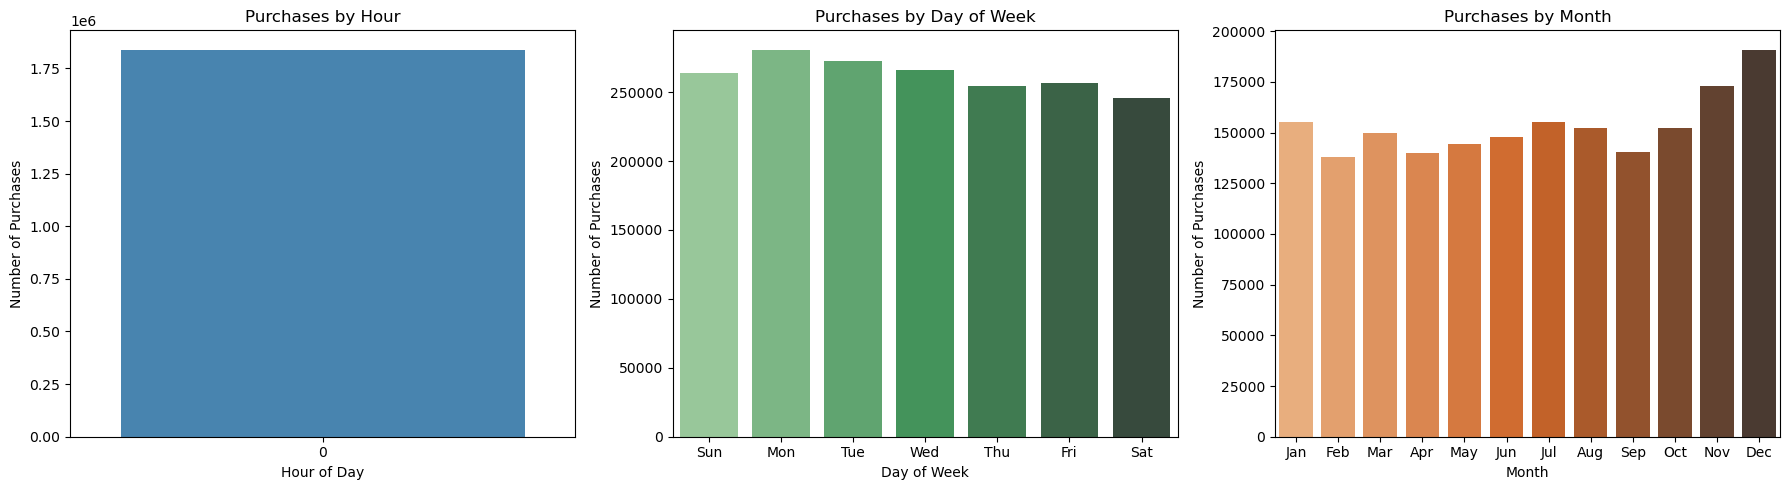

In [24]:
from pyspark.sql.functions import hour, dayofweek, month
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Extract hour, day of week, and month
cleaned_data = cleaned_data.withColumn("Hour", hour(col("Order Date"))) \
                           .withColumn("DayOfWeek", dayofweek(col("Order Date"))) \
                           .withColumn("Month", month(col("Order Date")))

# 2. Group and count purchases
hourly = cleaned_data.groupBy("Hour").count().orderBy("Hour").toPandas()
daily = cleaned_data.groupBy("DayOfWeek").count().orderBy("DayOfWeek").toPandas()
monthly = cleaned_data.groupBy("Month").count().orderBy("Month").toPandas()

# 3. Plot the data
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Hourly
sns.barplot(x="Hour", y="count", data=hourly, ax=axes[0], palette="Blues_d")
axes[0].set_title("Purchases by Hour")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Number of Purchases")

# Daily
day_labels = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
sns.barplot(x="DayOfWeek", y="count", data=daily, ax=axes[1], palette="Greens_d")
axes[1].set_title("Purchases by Day of Week")
axes[1].set_xlabel("Day of Week")
axes[1].set_ylabel("Number of Purchases")
axes[1].set_xticklabels(day_labels)

# Monthly
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
sns.barplot(x="Month", y="count", data=monthly, ax=axes[2], palette="Oranges_d")
axes[2].set_title("Purchases by Month")
axes[2].set_xlabel("Month")
axes[2].set_ylabel("Number of Purchases")
axes[2].set_xticklabels(month_labels)

plt.tight_layout()
plt.show()



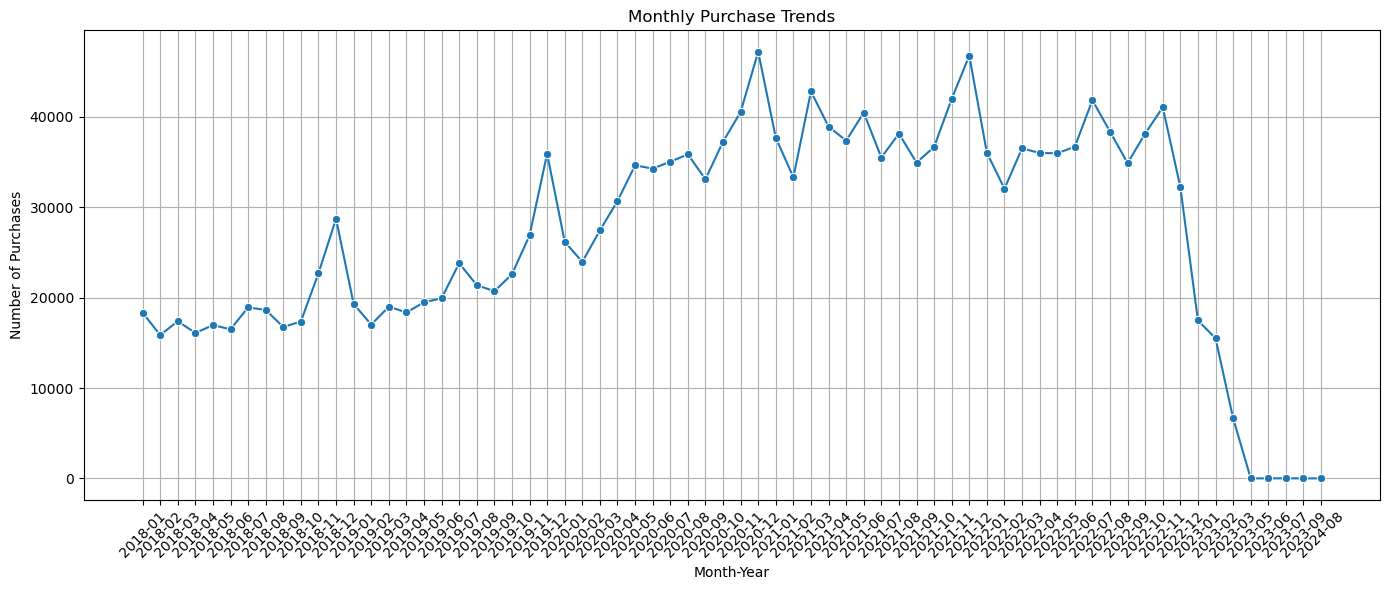

In [25]:
from pyspark.sql.functions import date_format
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract Month-Year from 'Order Date'
monthly_data = cleaned_data.withColumn("MonthYear", date_format(col("Order Date"), "yyyy-MM"))

# 2. Group by MonthYear and count number of purchases
monthly_trends = monthly_data.groupBy("MonthYear").count().orderBy("MonthYear")

# 3. Convert to Pandas for visualization
monthly_trends_pd = monthly_trends.toPandas()

# 4. Plot
plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_trends_pd, x="MonthYear", y="count", marker="o")
plt.title("Monthly Purchase Trends")
plt.xlabel("Month-Year")
plt.ylabel("Number of Purchases")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()



/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/2807309611.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Year", y="count", data=yearly_trends_pd, palette="mako")


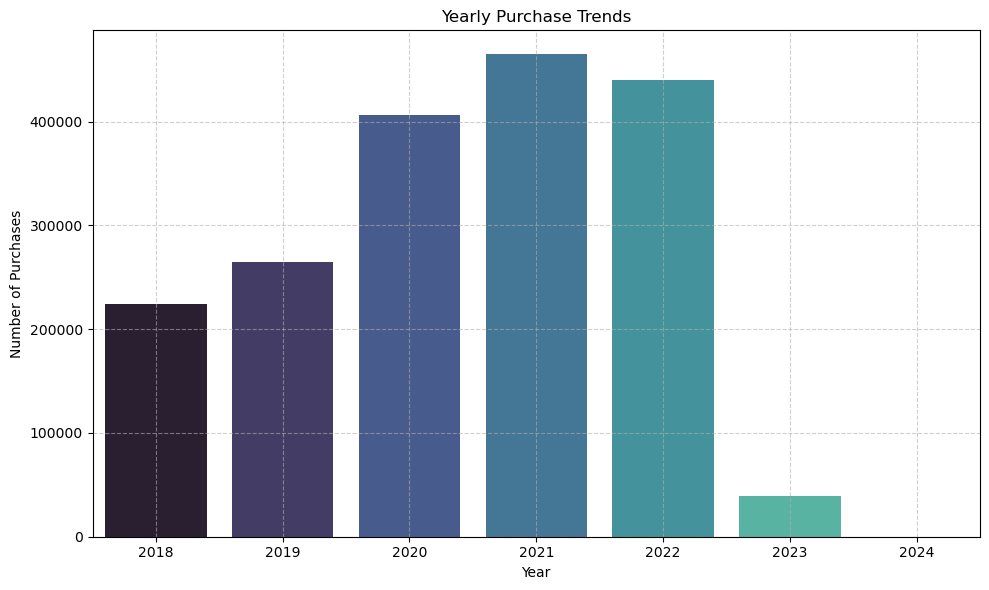

In [26]:
from pyspark.sql.functions import year
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract year from Order Date
yearly_data = cleaned_data.withColumn("Year", year(col("Order Date")))

# 2. Group by Year and count purchases
yearly_trends = yearly_data.groupBy("Year").count().orderBy("Year")

# 3. Convert to Pandas for visualization
yearly_trends_pd = yearly_trends.toPandas()

# 4. Plot
plt.figure(figsize=(10, 6))
sns.barplot(x="Year", y="count", data=yearly_trends_pd, palette="mako")
plt.title("Yearly Purchase Trends")
plt.xlabel("Year")
plt.ylabel("Number of Purchases")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()



## 3.2 Customer Demographics vs Purchase Frequency <font color = red>[5 marks]</font> <br>
Analyse the trends between the customer deographics and the purchase frequency

/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_20779/113794134.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=gender_freq_pd, x="Q-demos-gender", y="purchase_count", ax=axes[0], palette="coolwarm")
/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_20779/113794134.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=income_freq_pd, x="Q-demos-income", y="purchase_count", ax=axes[1], palette="crest")


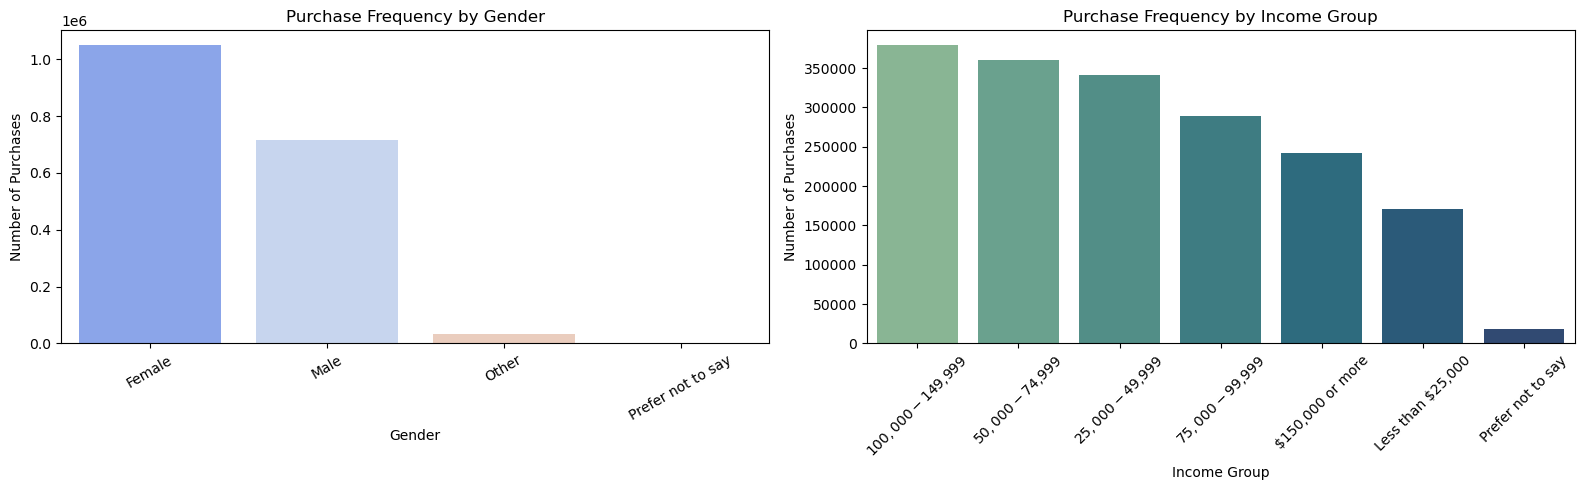

In [28]:
from pyspark.sql.functions import count
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Group by Gender and count purchases
gender_freq = cleaned_data.groupBy("Q-demos-gender").agg(count("*").alias("purchase_count")).orderBy("purchase_count", ascending=False)

# 2. Group by Income and count purchases
income_freq = cleaned_data.groupBy("Q-demos-income").agg(count("*").alias("purchase_count")).orderBy("purchase_count", ascending=False)

# 3. Convert to Pandas for visualization
gender_freq_pd = gender_freq.toPandas()
income_freq_pd = income_freq.toPandas()

# 4. Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gender
sns.barplot(data=gender_freq_pd, x="Q-demos-gender", y="purchase_count", ax=axes[0], palette="coolwarm")
axes[0].set_title("Purchase Frequency by Gender")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Number of Purchases")
axes[0].tick_params(axis='x', rotation=30)

# Income
sns.barplot(data=income_freq_pd, x="Q-demos-income", y="purchase_count", ax=axes[1], palette="crest")
axes[1].set_title("Purchase Frequency by Income Group")
axes[1].set_xlabel("Income Group")
axes[1].set_ylabel("Number of Purchases")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()



## 3.3 Purchase behavior weekend vs weekday <font color = red>[5 marks]</font> <br>

Compare the purchase behavior of customer's on weekdays vs. weekends.

/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_20779/4133495719.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=daytype_counts_pd, x="DayType", y="count", palette="pastel")


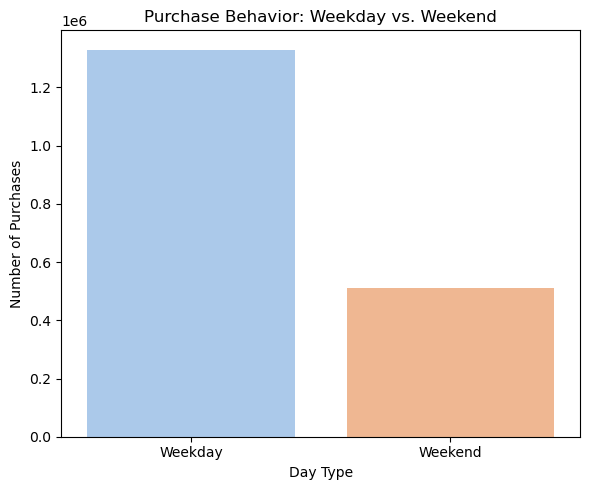

In [30]:
from pyspark.sql.functions import dayofweek, when
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract Day of Week (1 = Sunday, 7 = Saturday) and classify as Weekday/Weekend
cleaned_data = cleaned_data.withColumn("DayOfWeek", dayofweek(col("Order Date")))
cleaned_data = cleaned_data.withColumn("DayType", when(col("DayOfWeek").isin(1, 7), "Weekend").otherwise("Weekday"))

# 2. Group by DayType and count purchases
daytype_counts = cleaned_data.groupBy("DayType").count()

# 3. Convert to Pandas for visualization
daytype_counts_pd = daytype_counts.toPandas()

# 4. Plot
plt.figure(figsize=(6, 5))
sns.barplot(data=daytype_counts_pd, x="DayType", y="count", palette="pastel")
plt.title("Purchase Behavior: Weekday vs. Weekend")
plt.xlabel("Day Type")
plt.ylabel("Number of Purchases")
plt.tight_layout()
plt.show()


## 3.4 Frequently purchased product pairs <font color = red>[5 marks]</font> <br>

Analyze how frequently products are purchased together (also known as Market Basket Analysis)


/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/1389185961.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pair_counts_pd, y="PairKey", x="count", palette="Blues_d")
/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/1389185961.py:55: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


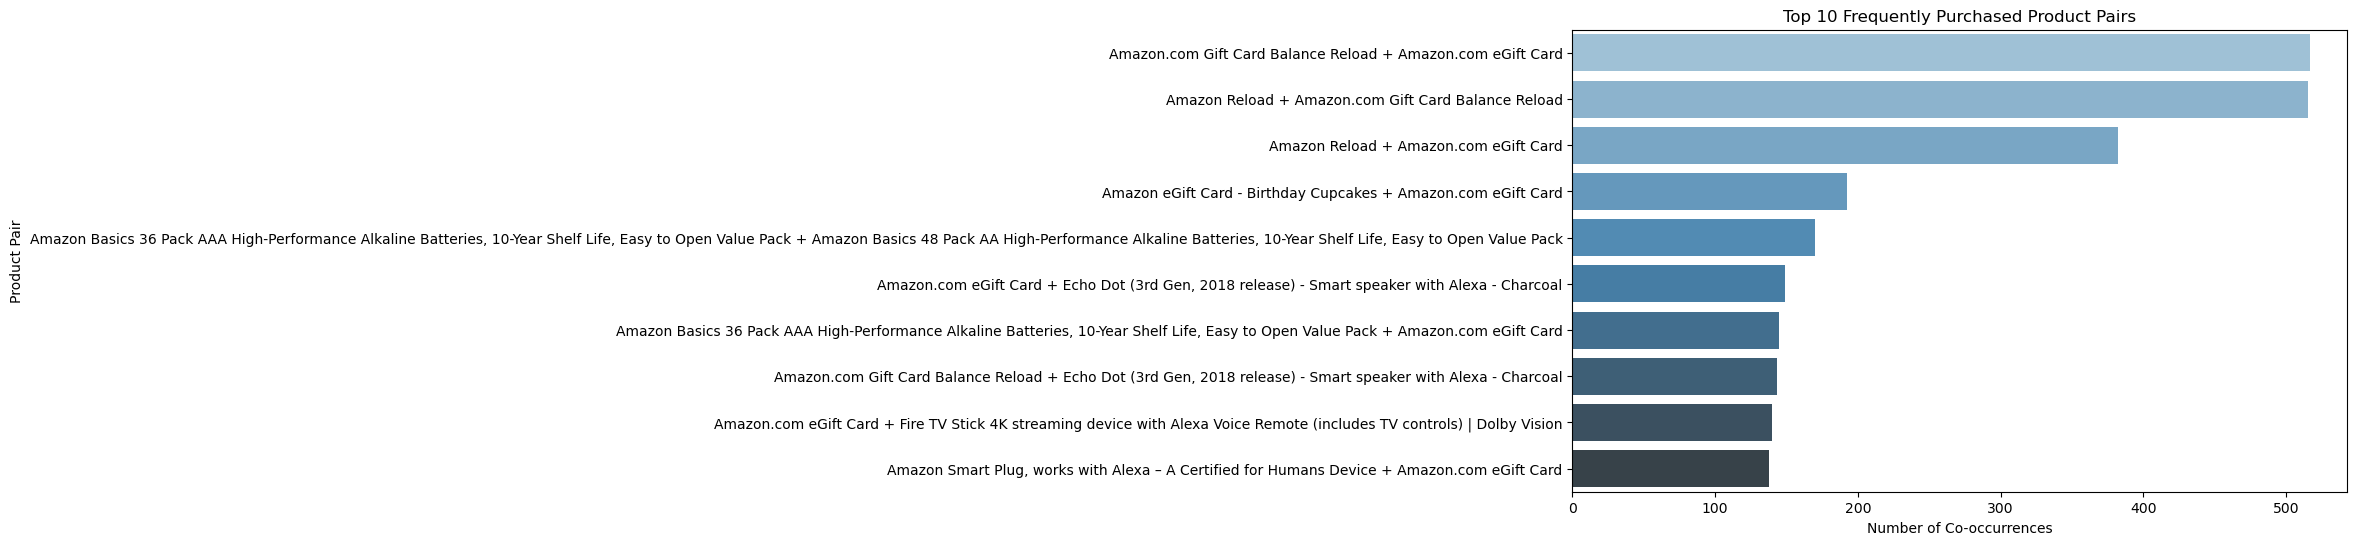

In [31]:
from pyspark.sql.functions import collect_set, explode, col, size, array_sort, concat_ws
import itertools
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pyspark.sql.functions import col, count

# Step: Filter top 100 most frequent product titles to reduce memory usage
top_titles_df = cleaned_data.groupBy("Title") \
    .agg(count("*").alias("freq")) \
    .orderBy("freq", ascending=False) \
    .limit(100)

# Collect top titles into Python list
top_titles_list = [row["Title"] for row in top_titles_df.collect()]

# Filter original data down to only those top products
filtered_data = cleaned_data.filter(col("Title").isin(top_titles_list))

# 1. Group items bought together by customer and order (optional: assume one order per customer)
basket_df = filtered_data.groupBy("Survey ResponseID") \
    .agg(collect_set("Title").alias("Items")) \
    .filter(size(col("Items")) > 1)  # Only consider baskets with more than 1 item

# 2. Create item pairs
def generate_pairs(items):
    return list(itertools.combinations(sorted(items), 2))

spark.udf.register("generate_pairs", generate_pairs)

from pyspark.sql.types import ArrayType, StringType
from pyspark.sql.functions import udf

pair_udf = udf(lambda x: generate_pairs(x), ArrayType(ArrayType(StringType())))
pairs_df = basket_df.withColumn("Pairs", pair_udf("Items")).select("Pairs")

# 3. Explode pairs
exploded_pairs = pairs_df.select(explode("Pairs").alias("Pair"))

# 4. Convert pair array to string for grouping
exploded_pairs = exploded_pairs.withColumn("PairKey", concat_ws(" + ", col("Pair")))

# 5. Count most frequent item pairs
pair_counts = exploded_pairs.groupBy("PairKey").count().orderBy("count", ascending=False)

# 6. Convert to Pandas for visualization
pair_counts_pd = pair_counts.limit(10).toPandas()

# 7. Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=pair_counts_pd, y="PairKey", x="count", palette="Blues_d")
plt.title("Top 10 Frequently Purchased Product Pairs")
plt.xlabel("Number of Co-occurrences")
plt.ylabel("Product Pair")
plt.tight_layout()
plt.show()


## 3.5 Examine Product Performance <font color = red>[5 marks]</font> <br>

Examine the performance of products by calculating revenue and item popularity.

/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/836577672.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_categories, y="Category", x="Total_Revenue", palette="viridis")


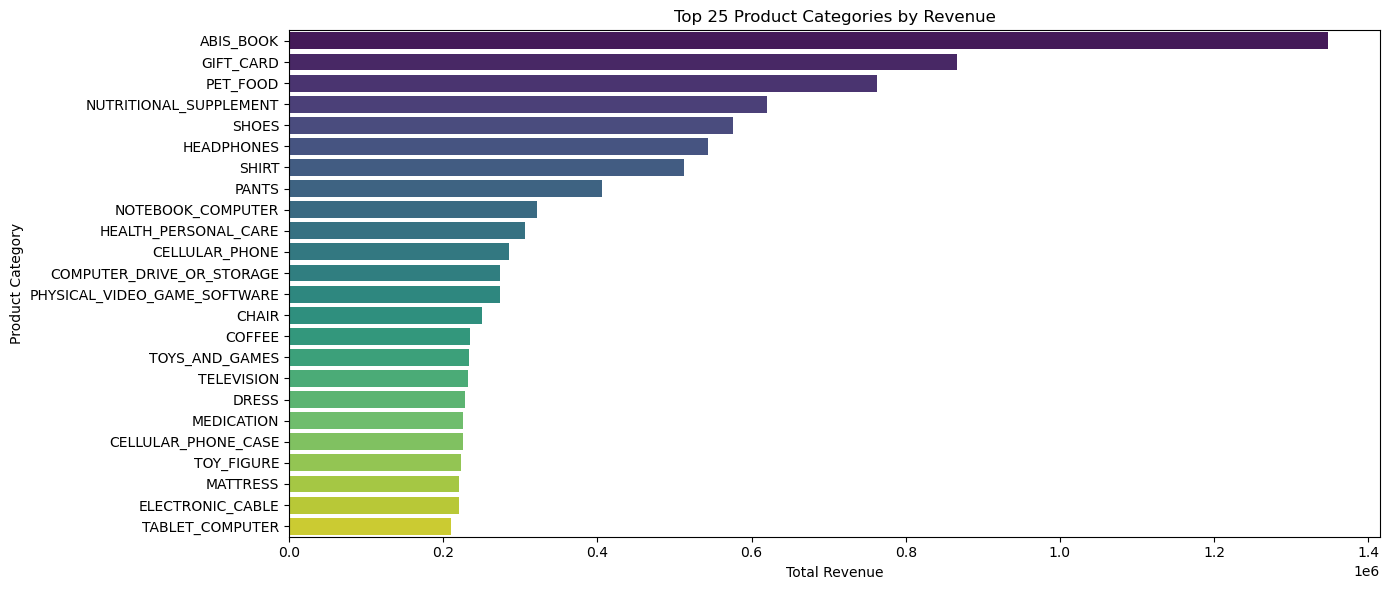

In [35]:
from pyspark.sql.functions import sum as spark_sum, count, col
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Create a TotalAmount column
cleaned_data = cleaned_data.withColumn("TotalAmount", col("Purchase Price Per Unit") * col("Quantity"))

# Step 2: Group by Category to get total revenue and units sold
product_perf = cleaned_data.groupBy("Category").agg(
    spark_sum("TotalAmount").alias("Total_Revenue"),
    count("Title").alias("Units_Sold")
).orderBy("Total_Revenue", ascending=False)

# Step 3: Convert top 25 categories to Pandas for plotting
top_categories = product_perf.limit(25).toPandas()

# Step 4: Plot
plt.figure(figsize=(14, 6))
sns.barplot(data=top_categories, y="Category", x="Total_Revenue", palette="viridis")
plt.title("Top 25 Product Categories by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


## 3.6 Top products by quantity <font color = red>[5 marks]</font> <br>

Identify the most frequently purchased products.

/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/88940451.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10_products, x="Total_Quantity", y="Title", palette="coolwarm")


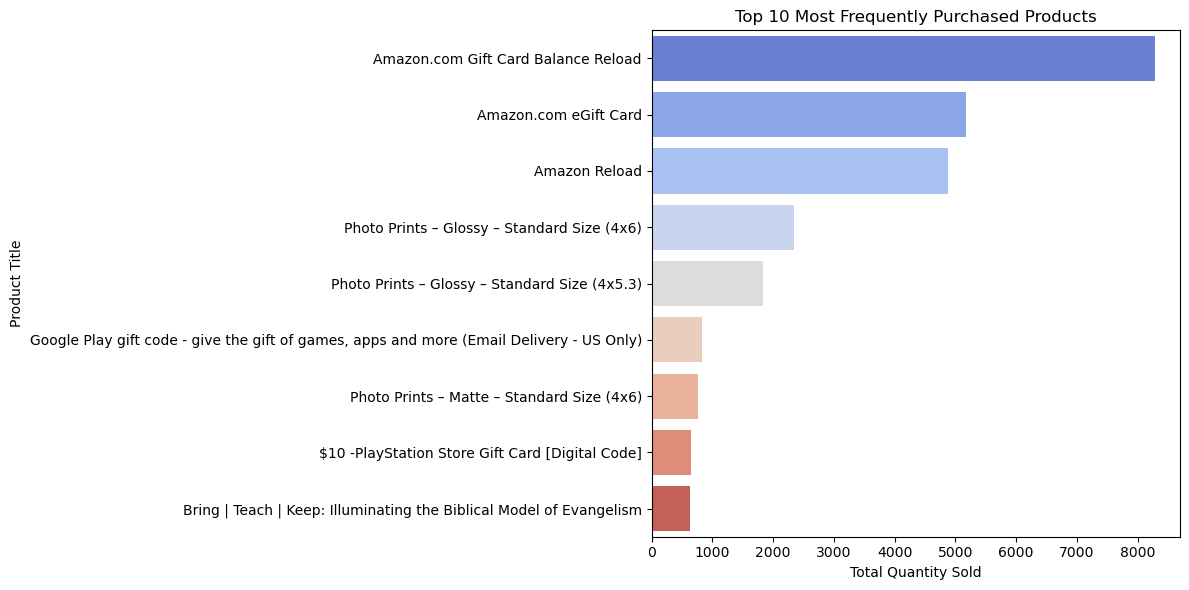

In [37]:
from pyspark.sql.functions import sum as spark_sum
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Group by product title and sum total quantity sold
top_products = cleaned_data.groupBy("Title").agg(
    spark_sum("Quantity").alias("Total_Quantity")
).orderBy("Total_Quantity", ascending=False)

# 2. Convert top 10 products to Pandas
top_10_products = top_products.limit(10).toPandas()

# 3. Plot
plt.figure(figsize=(12, 6))
sns.barplot(data=top_10_products, x="Total_Quantity", y="Title", palette="coolwarm")
plt.title("Top 10 Most Frequently Purchased Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Title")
plt.tight_layout()
plt.show()


## 3.7 Distribution of Purchases by State <font color = red>[5 marks]</font> <br>

Analyze the distribution of purchases across states and categories.

/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/2587247066.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_states, x="Total_Purchases", y="Shipping Address State", palette="magma")


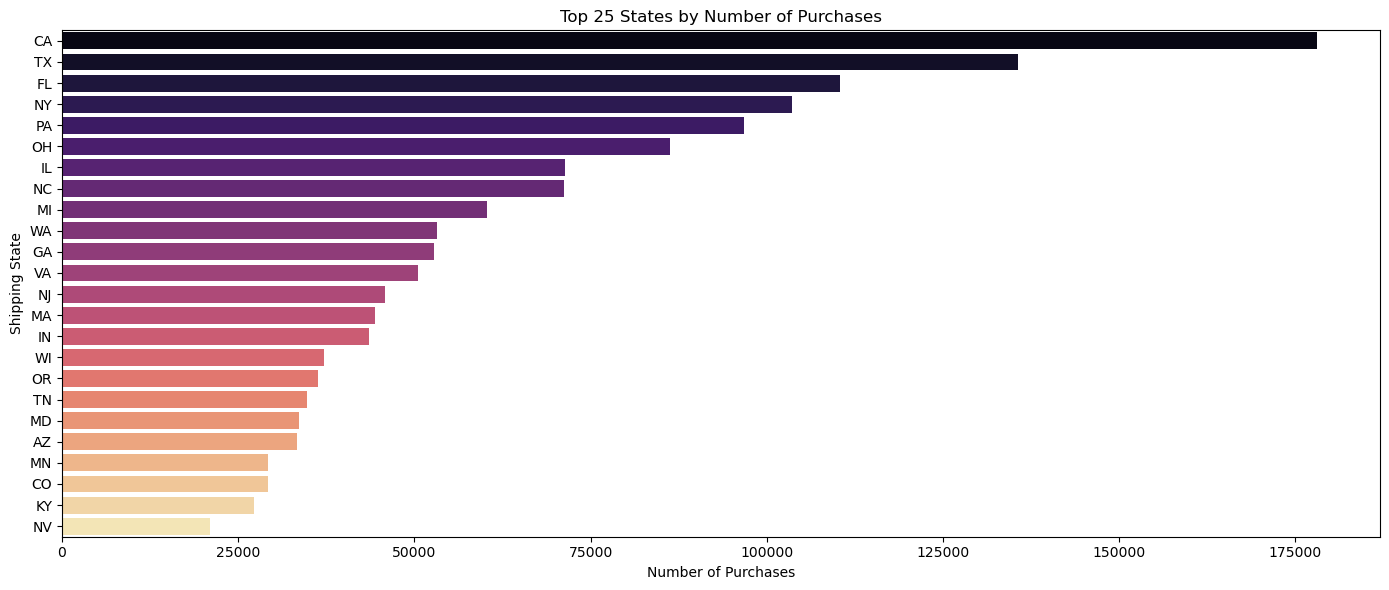

In [39]:
from pyspark.sql.functions import count
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Group by Shipping Address State and count purchases
state_distribution = cleaned_data.groupBy("Shipping Address State").agg(
    count("*").alias("Total_Purchases")
).orderBy("Total_Purchases", ascending=False)

# 2. Convert Top 25 states to Pandas
top_states = state_distribution.limit(25).toPandas()

# 3. Plot
plt.figure(figsize=(14, 6))
sns.barplot(data=top_states, x="Total_Purchases", y="Shipping Address State", palette="magma")
plt.title("Top 25 States by Number of Purchases")
plt.xlabel("Number of Purchases")
plt.ylabel("Shipping State")
plt.tight_layout()
plt.show()


## 3.8 Price vs Product Quantity <font color = red>[5 marks]</font> <br>

Identify the Relationship between Price and Quantity

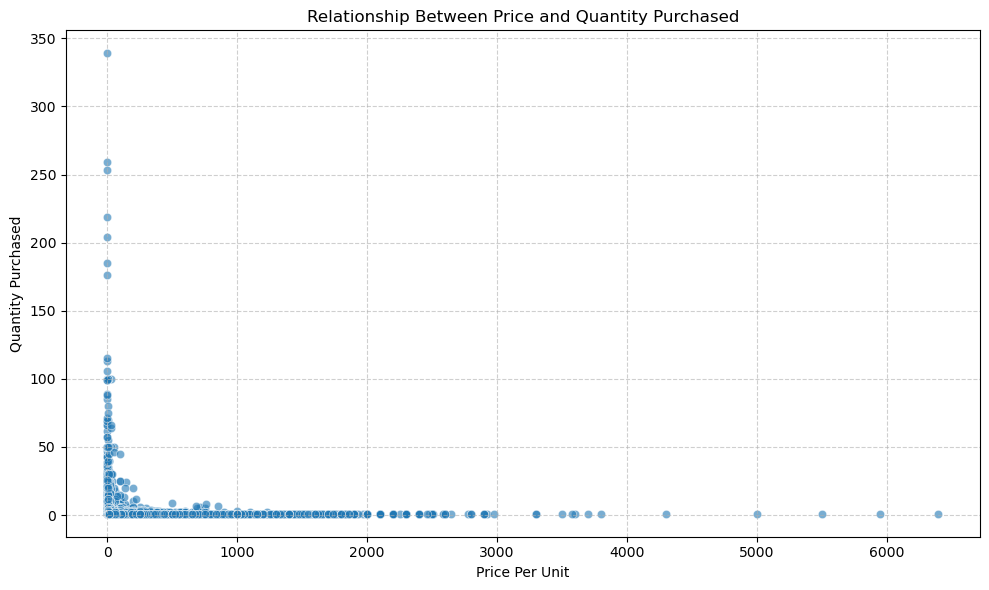

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Select relevant columns and drop nulls for clean plotting
price_qty = cleaned_data.select("Purchase Price Per Unit", "Quantity") \
    .dropna()

# 2. Convert to Pandas for visualization
price_qty_pd = price_qty.toPandas()

# 3. Plot: Scatter Plot of Price vs Quantity
plt.figure(figsize=(10, 6))
sns.scatterplot(data=price_qty_pd, x="Purchase Price Per Unit", y="Quantity", alpha=0.6)
plt.title("Relationship Between Price and Quantity Purchased")
plt.xlabel("Price Per Unit")
plt.ylabel("Quantity Purchased")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## 3.9 Analyse the spending KPIs <font color = red>[5 marks]</font> <br>


A popular KPI is average spend per customer. Calculate this metric as the ratio of total transaction amount from non-recurring payments divided by the total number of customers who made a purchase

/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/2193327915.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=kpi_df, x="Metric", y="Value", palette="Set2")


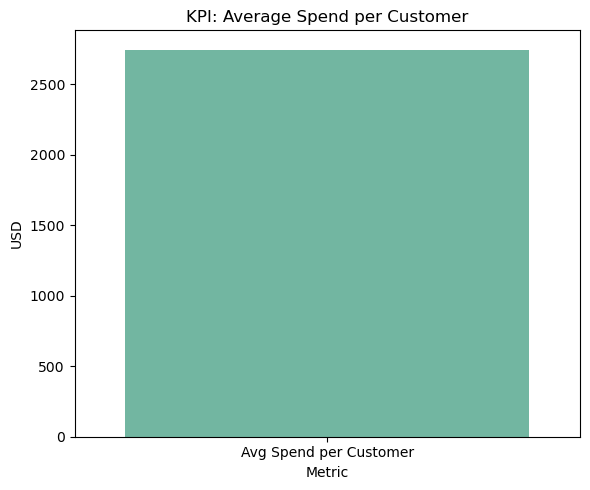

In [44]:
from pyspark.sql.functions import col, sum as spark_sum, countDistinct
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure TotalAmount column exists
cleaned_data = cleaned_data.withColumn("TotalAmount", col("Purchase Price Per Unit") * col("Quantity"))

# 2. Compute total revenue
total_revenue = cleaned_data.agg(spark_sum("TotalAmount")).collect()[0][0]

# 3. Compute total unique customers
total_customers = cleaned_data.select("Survey ResponseID").distinct().count()

# 4. Calculate average spend per customer
avg_spend_per_customer = total_revenue / total_customers

# 5. Prepare for plot
kpi_df = pd.DataFrame({
    "Metric": ["Avg Spend per Customer"],
    "Value": [avg_spend_per_customer]
})

# 6. Plot
plt.figure(figsize=(6, 5))
sns.barplot(data=kpi_df, x="Metric", y="Value", palette="Set2")
plt.title("KPI: Average Spend per Customer")
plt.ylabel("USD")
plt.tight_layout()
plt.show()


Analyse the Repeat Purchase Behavior of Customers

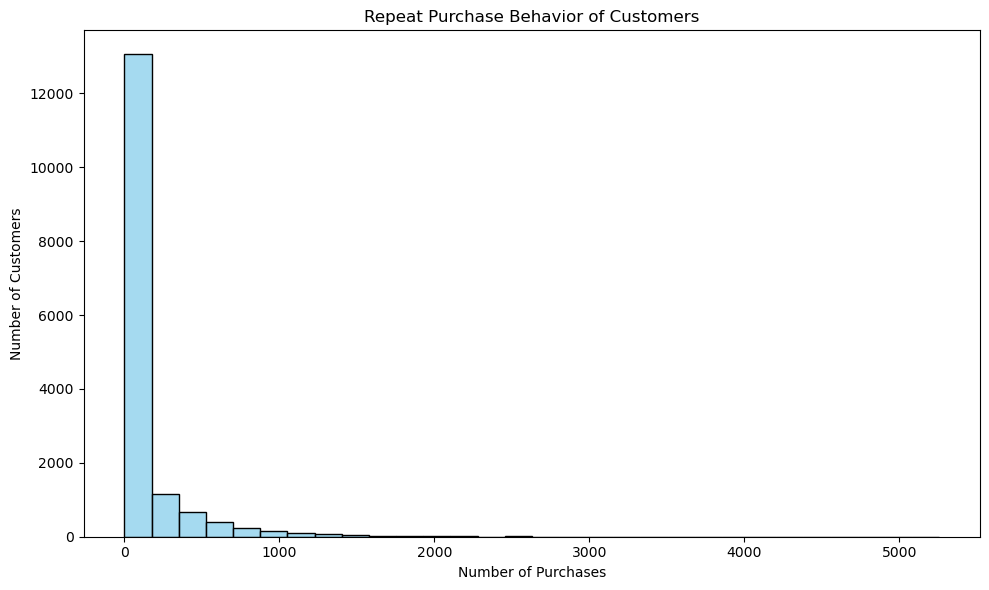

In [46]:
from pyspark.sql.functions import count
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Count number of purchases per customer
repeat_df = cleaned_data.groupBy("Survey ResponseID") \
    .agg(count("*").alias("Purchase_Count"))

# 2. Convert to Pandas for visualization
repeat_pd = repeat_df.toPandas()

# 3. Plot: Distribution of purchase frequency
plt.figure(figsize=(10, 6))
sns.histplot(repeat_pd["Purchase_Count"], bins=30, kde=False, color="skyblue")
plt.title("Repeat Purchase Behavior of Customers")
plt.xlabel("Number of Purchases")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


Analyse the top 10 high-engagement customers

/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/847267162.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_customers, x="Total_Spent", y="Survey ResponseID", palette="rocket")


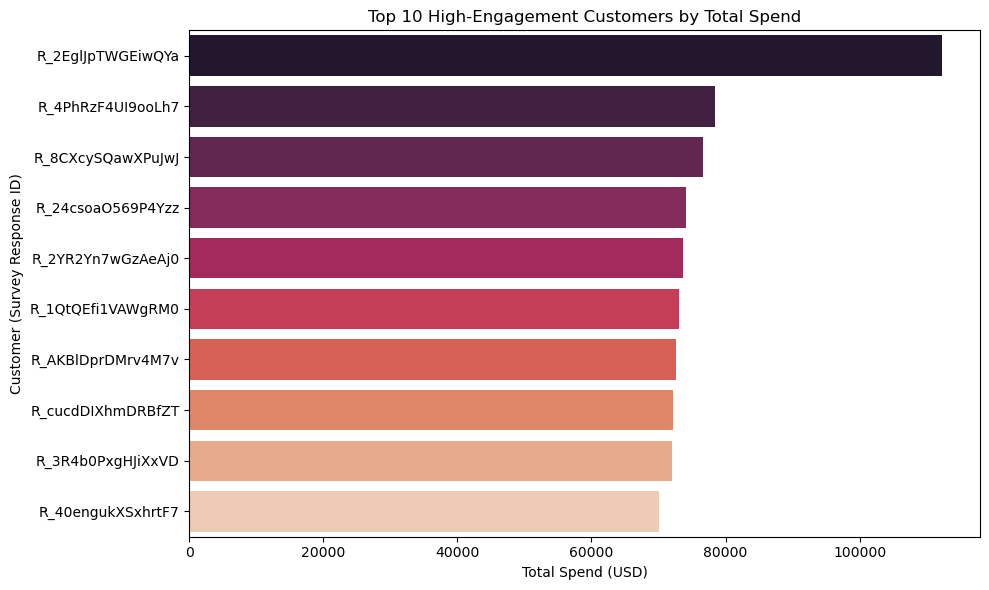

In [48]:
from pyspark.sql.functions import col, sum as spark_sum
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure TotalAmount is defined
cleaned_data = cleaned_data.withColumn("TotalAmount", col("Purchase Price Per Unit") * col("Quantity"))

# 2. Group by customer and calculate total spend
high_engagement = cleaned_data.groupBy("Survey ResponseID") \
    .agg(spark_sum("TotalAmount").alias("Total_Spent")) \
    .orderBy("Total_Spent", ascending=False) \
    .limit(10)

# 3. Convert to Pandas for visualization
top_customers = high_engagement.toPandas()

# 4. Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=top_customers, x="Total_Spent", y="Survey ResponseID", palette="rocket")
plt.title("Top 10 High-Engagement Customers by Total Spend")
plt.xlabel("Total Spend (USD)")
plt.ylabel("Customer (Survey Response ID)")
plt.tight_layout()
plt.show()


## 3.10 Seasonal trends in product purchases and their impact on revenues <font color = red>[5 marks]</font> <br>

Investigate the seasonal trends in product purchases and their impact on the overall revenue.

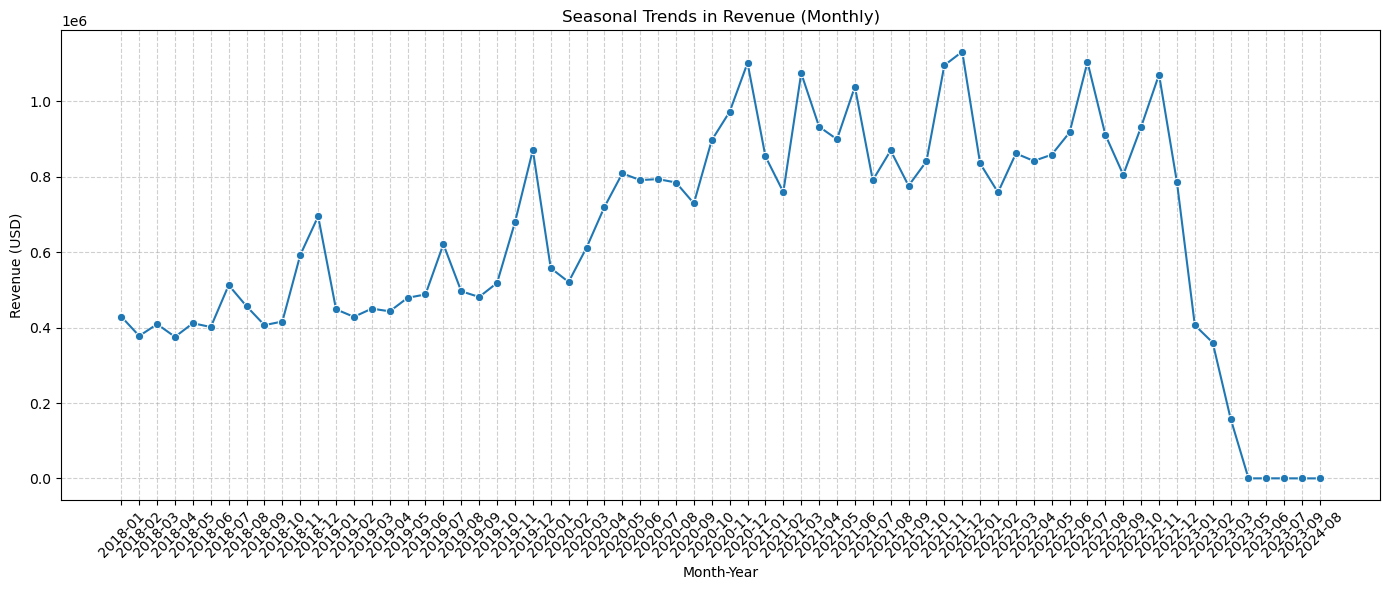

In [50]:
from pyspark.sql.functions import year, month, col, sum as spark_sum
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure TotalAmount is defined
cleaned_data = cleaned_data.withColumn("TotalAmount", col("Purchase Price Per Unit") * col("Quantity"))

# 2. Extract year and month
seasonal_data = cleaned_data.withColumn("Year", year(col("Order Date"))) \
                            .withColumn("Month", month(col("Order Date")))

# 3. Group by Year and Month, summing revenue
seasonal_trends = seasonal_data.groupBy("Year", "Month") \
    .agg(spark_sum("TotalAmount").alias("Monthly_Revenue")) \
    .orderBy("Year", "Month")

# 4. Convert to Pandas
seasonal_trends_pd = seasonal_trends.toPandas()
seasonal_trends_pd["MonthYear"] = seasonal_trends_pd["Year"].astype(str) + "-" + seasonal_trends_pd["Month"].astype(str).str.zfill(2)

# 5. Plot
plt.figure(figsize=(14, 6))
sns.lineplot(data=seasonal_trends_pd, x="MonthYear", y="Monthly_Revenue", marker="o")
plt.title("Seasonal Trends in Revenue (Monthly)")
plt.xlabel("Month-Year")
plt.ylabel("Revenue (USD)")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


## 3.11 Customer location vs purchasing behavior <font color = red>[5 marks]</font> <br>

Examine the relationship between customer's location and their purchasing behaviors

/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/1384512027.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=state_revenue_pd.head(20), y="Shipping Address State", x="Total_Revenue", palette="crest")


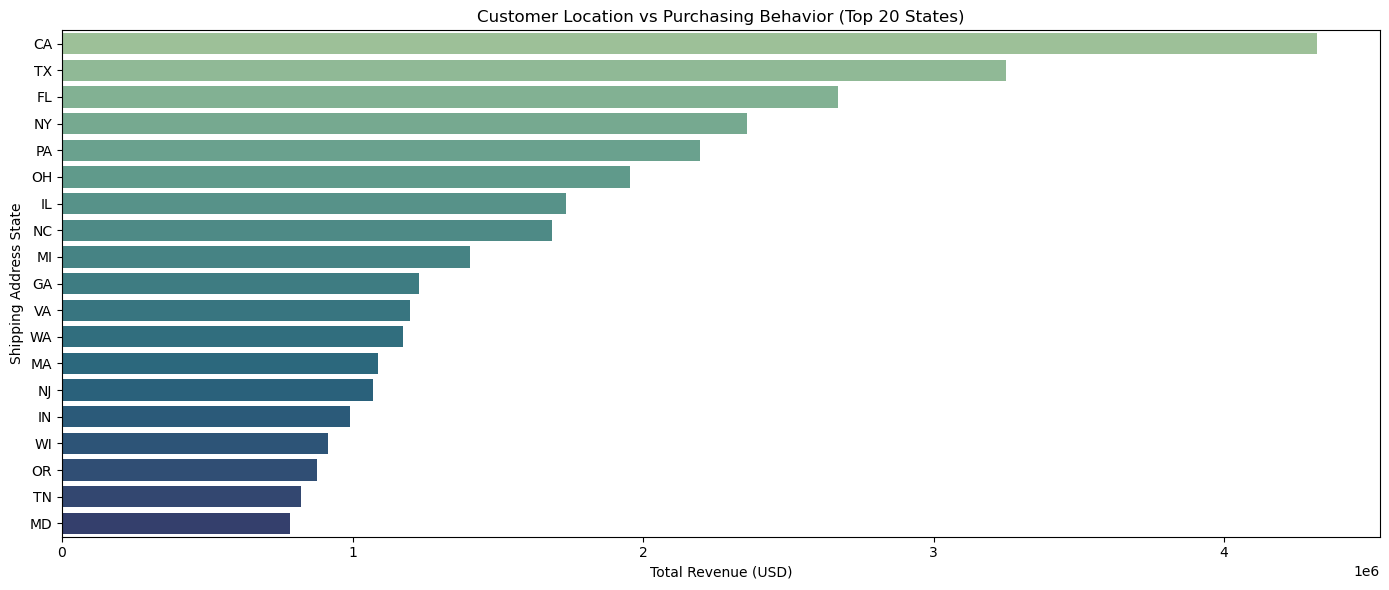

In [52]:
from pyspark.sql.functions import col, sum as spark_sum
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure TotalAmount is defined
cleaned_data = cleaned_data.withColumn("TotalAmount", col("Purchase Price Per Unit") * col("Quantity"))

# 2. Group by shipping state and calculate total spend
state_revenue = cleaned_data.groupBy("Shipping Address State") \
    .agg(spark_sum("TotalAmount").alias("Total_Revenue")) \
    .orderBy("Total_Revenue", ascending=False)

# 3. Convert to Pandas
state_revenue_pd = state_revenue.toPandas()

# 4. Plot revenue by state
plt.figure(figsize=(14, 6))
sns.barplot(data=state_revenue_pd.head(20), y="Shipping Address State", x="Total_Revenue", palette="crest")
plt.title("Customer Location vs Purchasing Behavior (Top 20 States)")
plt.xlabel("Total Revenue (USD)")
plt.ylabel("Shipping Address State")
plt.tight_layout()
plt.show()


#4. Customer Segmentation and Insights <font color = red>[45 marks]</font> <br>


## 4.1 Perform RFM Analysis <font color = red>[10 marks]</font> <br>

RFM Analysis is a powerful customer segmentation technique used to evaluate and quantify customer value based on three key dimensions:
- **Recency**,
- **Frequency**,
- **Monetary**.

This method is particularly effective in identifying high-value customers, optimizing marketing strategies, and improving customer retention in the e-commerce industry.


### 1. Recency (R)
Recency measures how recently a customer made a purchase Customers who have purchased more recently are more likely to respond to promotions and offers.
- **Application:** By ranking customers based on the number of days since their last transaction, you can prioritize those who are most engaged.

### 2. Frequency (F)
Frequency counts the number of purchases a customer has made over a given period.
Frequent purchasers tend to be more loyal and are often a source of recurring revenue.
- **Application:** Analyzing purchase frequency helps in identifying consistent buyers and understanding their buying patterns.

### 3. Monetary (M)
Monetary value represents the total amount of money a customer has spent.
Customers who spend more are often more profitable, making them ideal targets for retention and upsell strategies.
- **Application:** By assessing the monetary contribution, you can distinguish between high-value and low-value customers.


### Prepare data for RFM Analysis <font color = red>[2 marks]</font> <br>


In [55]:
from pyspark.sql.functions import col, datediff, max as spark_max, count as spark_count, sum as spark_sum

# 1. Ensure TotalAmount column is defined
cleaned_data = cleaned_data.withColumn("TotalAmount", col("Purchase Price Per Unit") * col("Quantity"))

# 2. Get the latest order date (reference date for recency)
latest_order_date = cleaned_data.agg(spark_max("Order Date")).collect()[0][0]

# 3. Calculate RFM metrics
rfm_df = cleaned_data.groupBy("Survey ResponseID").agg(
    datediff(lit(latest_order_date), spark_max("Order Date")).alias("Recency"),
    spark_count("*").alias("Frequency"),
    spark_sum("TotalAmount").alias("Monetary")
)

# 4. Filter out customers with zero or null monetary value (if any)
rfm_df = rfm_df.filter(col("Monetary").isNotNull() & (col("Monetary") > 0))

# 5. Show the RFM table
rfm_df.show(10, truncate=False)


+-----------------+-------+---------+------------------+
|Survey ResponseID|Recency|Frequency|Monetary          |
+-----------------+-------+---------+------------------+
|R_10TV1zyi4yCEEkl|525    |1124     |29788.359999999953|
|R_1QgWXnlpERvWjrY|645    |89       |1515.41           |
|R_1LBvKYfg8hgoloJ|1896   |7        |326.78000000000003|
|R_1mxX9jjBSLwxiDU|524    |248      |2765.2600000000007|
|R_297dOANqCntVXou|600    |588      |11329.400000000005|
|Easter           |730    |7        |49.55             |
|R_1CqGMkfiCiATbn4|528    |183      |5691.1500000000015|
|R_1N52McSjcCnVqIm|590    |11       |267.72            |
|R_1eWdieBjoYJXAYv|606    |965      |27099.969999999976|
|R_1esG9Jlh9NISLaO|529    |368      |6881.200000000002 |
+-----------------+-------+---------+------------------+
only showing top 10 rows



In [57]:
from pyspark.sql.functions import log1p
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Apply log transformation to handle skewness
rfm_log = rfm_df.select(
    col("Survey ResponseID"),
    log1p("Recency").alias("log_Recency"),
    log1p("Frequency").alias("log_Frequency"),
    log1p("Monetary").alias("log_Monetary")
)

# 2. Convert to Pandas for scikit-learn use
rfm_pd = rfm_log.toPandas()

# 3. Drop ID column for scaling/clustering
rfm_values = rfm_pd.drop(columns=["Survey ResponseID"])

# 4. Apply StandardScaler
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_values)

# 5. Optional: convert back to DataFrame with original column names
rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=rfm_values.columns)
rfm_scaled_df["Survey ResponseID"] = rfm_pd["Survey ResponseID"]

# Preview scaled data
rfm_scaled_df.head()


,log_Recency,log_Frequency,log_Monetary,Survey ResponseID
0,-1.213859,2.160130,2.010553,R_10TV1zyi4yCEEkl
1,-0.753767,0.990604,0.862926,R_1QgWXnlpERvWjrY
2,1.658053,-0.130136,0.272597,R_1LBvKYfg8hgoloJ
3,-1.218119,1.461818,1.094606,R_1mxX9jjBSLwxiDU
4,-0.915426,1.860488,1.638008,R_297dOANqCntVXou


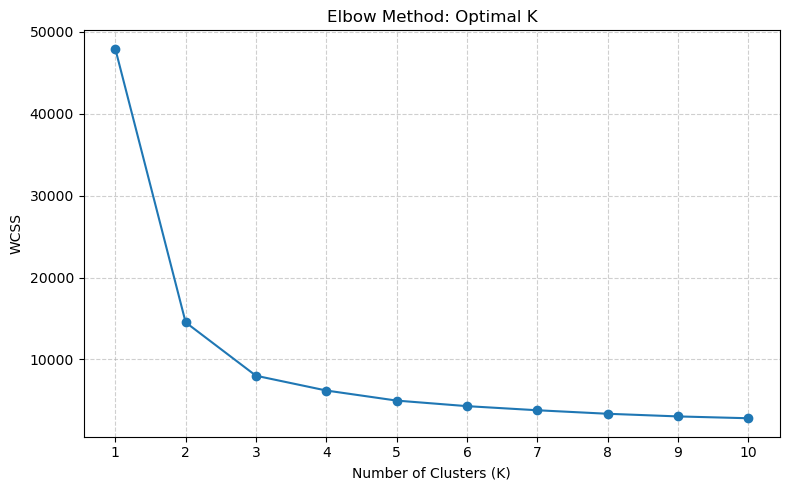

In [59]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Prepare data: use only RFM log-scaled columns (exclude ID)
rfm_features = rfm_scaled_df[["log_Recency", "log_Frequency", "log_Monetary"]]

# Range of cluster numbers to test
wcss = []
K_range = range(1, 11)

# Calculate WCSS for each K
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_features)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker='o')
plt.title("Elbow Method: Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(K_range)
plt.tight_layout()
plt.show()


In [61]:
from sklearn.cluster import KMeans
import pandas as pd

# 1. Fit KMeans with optimal K (you can change 4 to whatever the elbow showed)
k_optimal = 4
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
rfm_scaled_df["Cluster"] = kmeans.fit_predict(rfm_scaled_df[["log_Recency", "log_Frequency", "log_Monetary"]])

# 2. (Optional) Inspect clustered segments
cluster_summary = rfm_scaled_df.groupby("Cluster")[["log_Recency", "log_Frequency", "log_Monetary"]].mean()
print(cluster_summary)

# 3. Merge cluster labels back to original RFM scores if needed
rfm_clustered = rfm_df.join(
    spark.createDataFrame(rfm_scaled_df[["Survey ResponseID", "Cluster"]]),
    on="Survey ResponseID",
    how="left"
)

# 4. Show a sample of clustered data
rfm_clustered.show(10, truncate=False)


         log_Recency  log_Frequency  log_Monetary
Cluster                                          
0          -0.746886       0.550151      0.669000
1           1.242338      -0.707527     -0.692754
2          -0.273856      -0.638692     -0.629455
3          -0.981255       1.643286      1.538356


+-----------------+-------+---------+------------------+-------+
|Survey ResponseID|Recency|Frequency|Monetary          |Cluster|
+-----------------+-------+---------+------------------+-------+
|R_10TV1zyi4yCEEkl|525    |1124     |29788.359999999953|3      |
|R_1QgWXnlpERvWjrY|645    |89       |1515.41           |0      |
|R_1LBvKYfg8hgoloJ|1896   |7        |326.78000000000003|1      |
|R_1mxX9jjBSLwxiDU|524    |248      |2765.2600000000007|3      |
|R_297dOANqCntVXou|600    |588      |11329.400000000005|3      |
|Easter           |730    |7        |49.55             |2      |
|R_1CqGMkfiCiATbn4|528    |183      |5691.1500000000015|3      |
|R_1N52McSjcCnVqIm|590    |11       |267.72            |0      |
|R_1eWdieBjoYJXAYv|606    |965      |27099.969999999976|3      |
|R_1esG9Jlh9NISLaO|529    |368      |6881.200000000002 |3      |
+-----------------+-------+---------+------------------+-------+
only showing top 10 rows



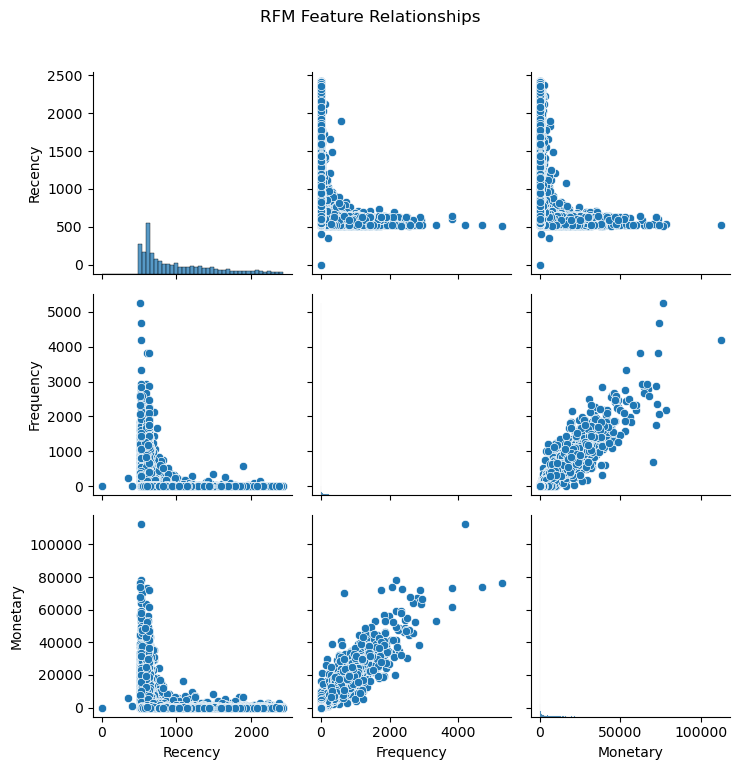

In [63]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Convert full RFM data to Pandas
rfm_pd_full = rfm_df.toPandas()

# 2. Optional: Add cluster labels if you've already done clustering
# rfm_pd_full = rfm_pd_full.merge(rfm_scaled_df[["Survey ResponseID", "Cluster"]], on="Survey ResponseID", how="left")

# 3. Generate pairplot
sns.pairplot(rfm_pd_full[["Recency", "Frequency", "Monetary"]])
plt.suptitle("RFM Feature Relationships", y=1.02)
plt.tight_layout()
plt.show()


### Behavioral Trends Analysis <font color = red>[8 marks]</font> <br>

Perform RFM analysis to study the behavior of customers to tailor marketing strategies

In [65]:
from pyspark.sql.functions import col, countDistinct, sum as spark_sum, max as spark_max, datediff, lit, log1p
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Step 1: Create TotalAmount column if not already done
cleaned_data = cleaned_data.withColumn("TotalAmount", col("Purchase Price Per Unit") * col("Quantity"))

# Step 2: Get the latest date in the dataset
latest_date = cleaned_data.agg(spark_max("Order Date")).collect()[0][0]

# Step 3: Calculate RFM metrics
rfm_df = cleaned_data.groupBy("Survey ResponseID").agg(
    datediff(lit(latest_date), spark_max("Order Date")).alias("Recency"),
    countDistinct("ASIN/ISBN (Product Code)").alias("Frequency"),
    spark_sum("TotalAmount").alias("Monetary")
)

# Step 4: Apply log transformation to reduce skewness
rfm_log_df = rfm_df.select(
    col("Survey ResponseID"),
    log1p("Recency").alias("log_Recency"),
    log1p("Frequency").alias("log_Frequency"),
    log1p("Monetary").alias("log_Monetary")
)

# Step 5: Convert to Pandas
rfm_pd = rfm_log_df.toPandas()

# Step 6: Normalize RFM values for clustering
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_pd[["log_Recency", "log_Frequency", "log_Monetary"]])

# Step 7: Convert back to DataFrame with IDs
rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=["log_Recency", "log_Frequency", "log_Monetary"])
rfm_scaled_df["Survey ResponseID"] = rfm_pd["Survey ResponseID"]

# Preview processed RFM data
rfm_scaled_df.head()


,log_Recency,log_Frequency,log_Monetary,Survey ResponseID
0,-1.213859,2.227032,2.010553,R_10TV1zyi4yCEEkl
1,-1.222388,1.954032,1.700143,R_1gG5xibh48txT6f
2,-1.196897,1.712399,1.445870,R_1esG9Jlh9NISLaO
3,-0.915426,1.918516,1.638008,R_297dOANqCntVXou
4,-1.243854,1.937849,1.699453,R_1jO4s7oht3pyKEc


In [67]:
from sklearn.cluster import KMeans
from pyspark.sql import SparkSession

# Step 1: Choose optimal number of clusters (e.g., k=4)
k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
rfm_scaled_df["Cluster"] = kmeans.fit_predict(rfm_scaled_df[["log_Recency", "log_Frequency", "log_Monetary"]])

# Step 2: Optional - inspect how clusters differ
cluster_summary = rfm_scaled_df.groupby("Cluster")[["log_Recency", "log_Frequency", "log_Monetary"]].mean()
print(cluster_summary)

# Step 3: Convert Pandas back to PySpark DataFrame
spark_df_with_clusters = spark.createDataFrame(rfm_scaled_df)

# Step 4: Show result
spark_df_with_clusters.show(10, truncate=False)


         log_Recency  log_Frequency  log_Monetary
Cluster                                          
0          -0.300159      -0.648644     -0.592876
1          -0.983248       1.678508      1.546178
2           1.230142      -0.672794     -0.691811
3          -0.771208       0.608382      0.744790
+-------------------+-------------------+------------------+-----------------+-------+
|log_Recency        |log_Frequency      |log_Monetary      |Survey ResponseID|Cluster|
+-------------------+-------------------+------------------+-----------------+-------+
|-1.2138587629489663|2.2270323678012383 |2.0105531992831978|R_10TV1zyi4yCEEkl|1      |
|-1.2223879527302997|1.9540320987523414 |1.7001434948452068|R_1gG5xibh48txT6f|1      |
|-1.196897245388455 |1.7123994021982252 |1.4458697122840063|R_1esG9Jlh9NISLaO|1      |
|-0.9154261682748323|1.9185155028931218 |1.6380080154287873|R_297dOANqCntVXou|1      |
|-1.2438541728745545|1.9378493659042413 |1.699453012559624 |R_1jO4s7oht3pyKEc|1      |
|-0.

Analyse the Cluster Distribution by Income <font color = red>[2 marks]</font> <br>


In [71]:
survey_df = survey


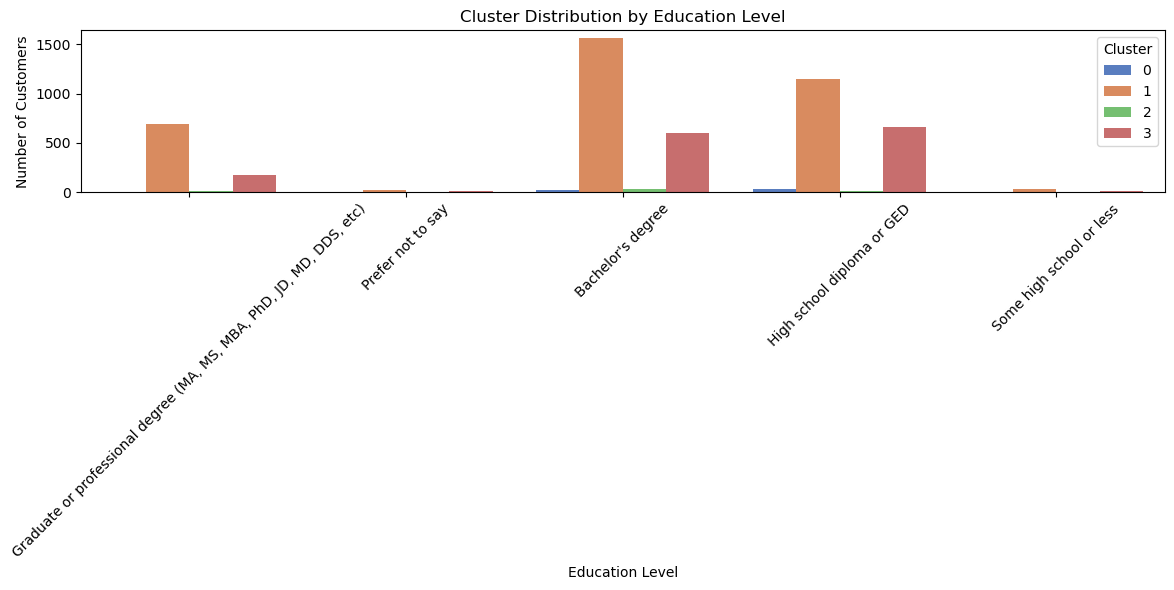

In [73]:
from pyspark.sql.functions import count
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Join RFM clusters with survey data (if not already done)
rfm_education_df = spark_df_with_clusters.join(
    survey_df,  # Make sure this DataFrame is defined
    on="Survey ResponseID",
    how="left"
)

# 2. Group by Cluster and Education
cluster_education_dist = rfm_education_df.groupBy("Cluster", "Q-demos-education") \
    .agg(count("*").alias("Customer_Count"))

# 3. Convert to Pandas for plotting
cluster_education_pd = cluster_education_dist.toPandas()

# 4. Plot
plt.figure(figsize=(12, 6))
sns.barplot(
    data=cluster_education_pd,
    x="Q-demos-education",
    y="Customer_Count",
    hue="Cluster",
    palette="muted"
)
plt.title("Cluster Distribution by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Analyse the Average Spending by Cluster <font color = red>[2 marks]</font> <br>


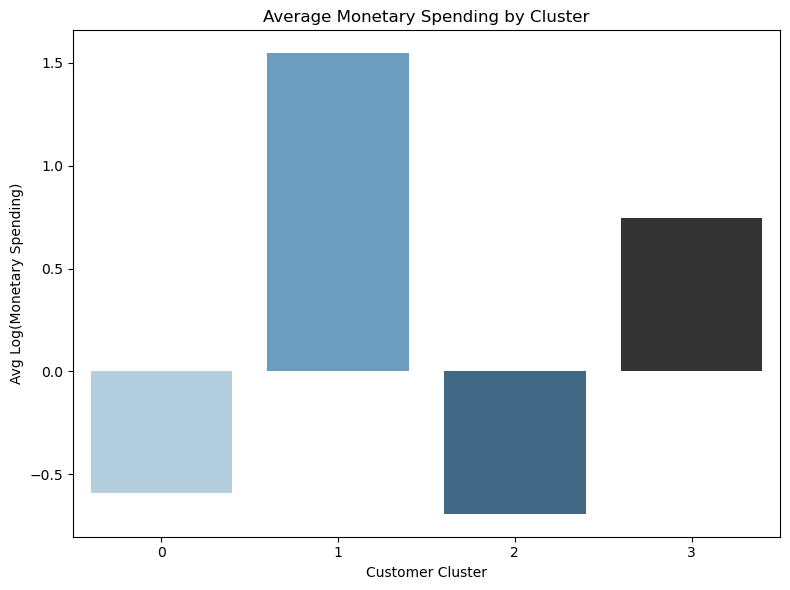

In [78]:
from pyspark.sql.functions import avg
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Compute average RFM values for each cluster
cluster_avg = spark_df_with_clusters.groupBy("Cluster").agg(
    avg("log_Recency").alias("Avg_Recency"),
    avg("log_Frequency").alias("Avg_Frequency"),
    avg("log_Monetary").alias("Avg_Monetary")
)

# 2. Convert to Pandas for visualization
cluster_avg_pd = cluster_avg.toPandas()

# 3. Plot average monetary value per cluster
plt.figure(figsize=(8, 6))
sns.barplot(data=cluster_avg_pd, x="Cluster", y="Avg_Monetary", hue="Cluster", palette="Blues_d", legend=False)
plt.title("Average Monetary Spending by Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Avg Log(Monetary Spending)")
plt.tight_layout()
plt.show()


Analyse the Purchase Frequency vs. Recency <font color = red>[2 marks]</font> <br>


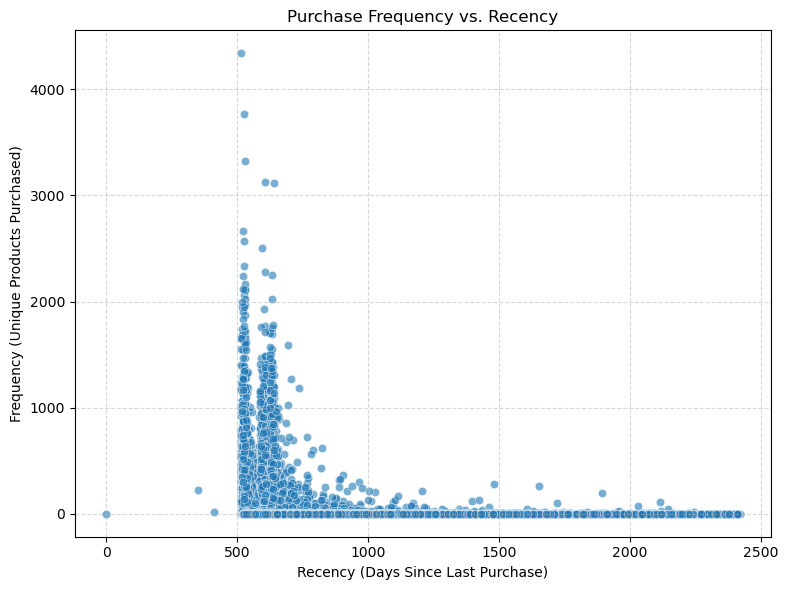

In [82]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Convert RFM data (with clusters, if available) to Pandas
rfm_plot_df = rfm_df.toPandas()  # or use rfm_scaled_df if log-transformed

# 2. Plot: Frequency vs. Recency
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=rfm_plot_df,
    x="Recency",
    y="Frequency",
    alpha=0.6
)
plt.title("Purchase Frequency vs. Recency")
plt.xlabel("Recency (Days Since Last Purchase)")
plt.ylabel("Frequency (Unique Products Purchased)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


Analyse the top categories by clusters <font color = red>[2 marks]</font> <br>


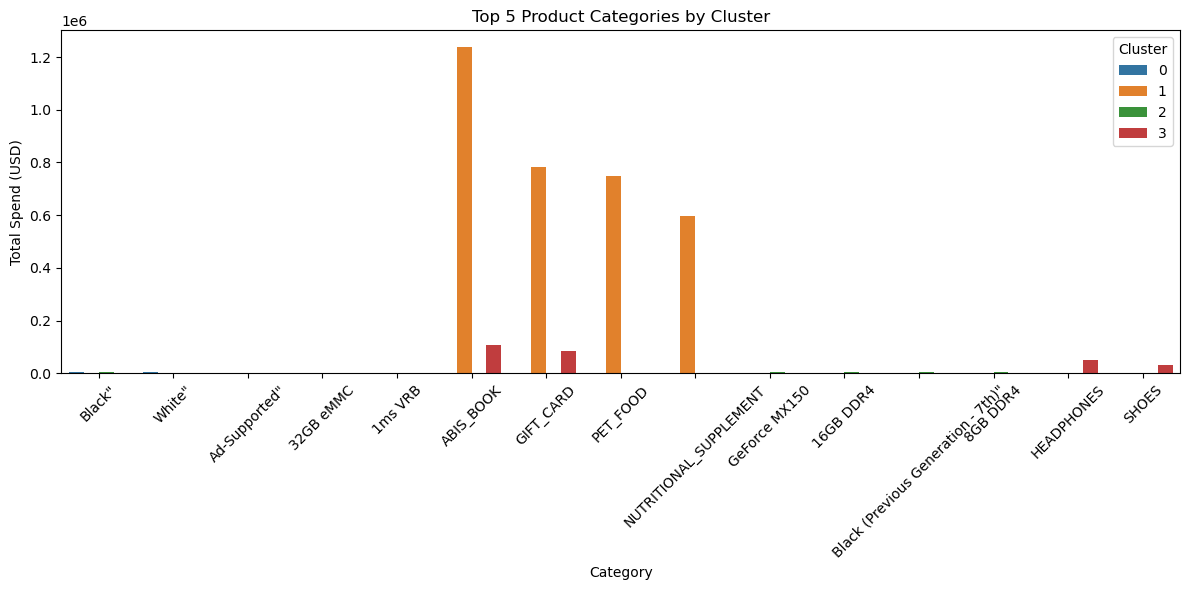

In [84]:
from pyspark.sql.functions import sum as spark_sum
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure TotalAmount is present
cleaned_data = cleaned_data.withColumn("TotalAmount", col("Purchase Price Per Unit") * col("Quantity"))

# 2. Join cleaned_data with cluster labels
clustered_data = cleaned_data.join(
    spark_df_with_clusters.select("Survey ResponseID", "Cluster"),
    on="Survey ResponseID",
    how="inner"
)

# 3. Group by Cluster and Category, compute total spending
category_cluster_spend = clustered_data.groupBy("Cluster", "Category") \
    .agg(spark_sum("TotalAmount").alias("Total_Spent"))

# 4. For each cluster, get top 5 categories (via window function)
from pyspark.sql.window import Window
from pyspark.sql.functions import row_number

window_spec = Window.partitionBy("Cluster").orderBy(col("Total_Spent").desc())
top_categories = category_cluster_spend.withColumn("rank", row_number().over(window_spec)) \
                                       .filter(col("rank") <= 5)

# 5. Convert to Pandas
top_categories_pd = top_categories.toPandas()

# 6. Plot top categories per cluster
plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_categories_pd,
    x="Category",
    y="Total_Spent",
    hue="Cluster",
    palette="tab10"
)
plt.title("Top 5 Product Categories by Cluster")
plt.xlabel("Category")
plt.ylabel("Total Spend (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 4.2 Insights <font color = red>[35 marks]</font> <br>


### 4.2.1 When to schedule effective promotions. <font color = red>[3 marks]</font> <br>

Compare sales across weekdays to schedule effective promotions

/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/1988394004.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=weekday_summary_pd, x="Weekday", y="Total_Sales", palette="viridis")


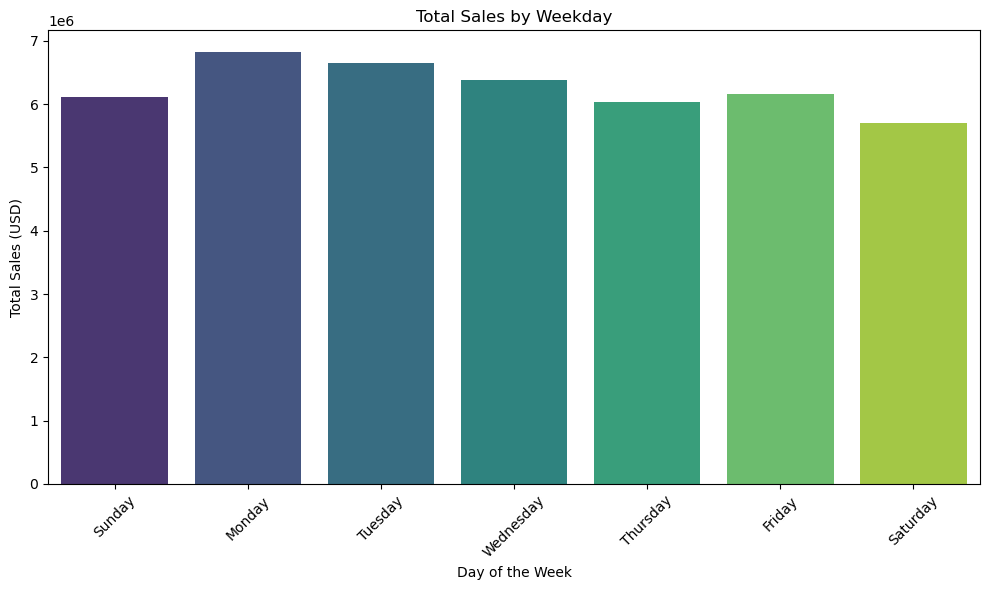

In [88]:
from pyspark.sql.functions import dayofweek, sum as spark_sum
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure TotalAmount column is present
cleaned_data = cleaned_data.withColumn("TotalAmount", col("Purchase Price Per Unit") * col("Quantity"))

# 2. Extract day of the week from 'Order Date' (1 = Sunday, 7 = Saturday)
weekday_sales = cleaned_data.withColumn("Weekday", dayofweek(col("Order Date")))

# 3. Group by weekday and sum total sales
weekday_summary = weekday_sales.groupBy("Weekday").agg(spark_sum("TotalAmount").alias("Total_Sales"))

# 4. Convert to Pandas for plotting
weekday_summary_pd = weekday_summary.toPandas().sort_values("Weekday")

# Optional: Map weekday numbers to names
weekday_labels = {
    1: "Sunday", 2: "Monday", 3: "Tuesday", 4: "Wednesday",
    5: "Thursday", 6: "Friday", 7: "Saturday"
}
weekday_summary_pd["Weekday"] = weekday_summary_pd["Weekday"].map(weekday_labels)

# 5. Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=weekday_summary_pd, x="Weekday", y="Total_Sales", palette="viridis")
plt.title("Total Sales by Weekday")
plt.xlabel("Day of the Week")
plt.ylabel("Total Sales (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 4.2.2 Top-selling Products <font color = red>[2 marks]</font> <br>

Identify top-selling products by considering revenue and engagement metrics

/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/1012167596.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_products_pd, x="Total_Revenue", y="Title", palette="mako")
/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/1012167596.py:25: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


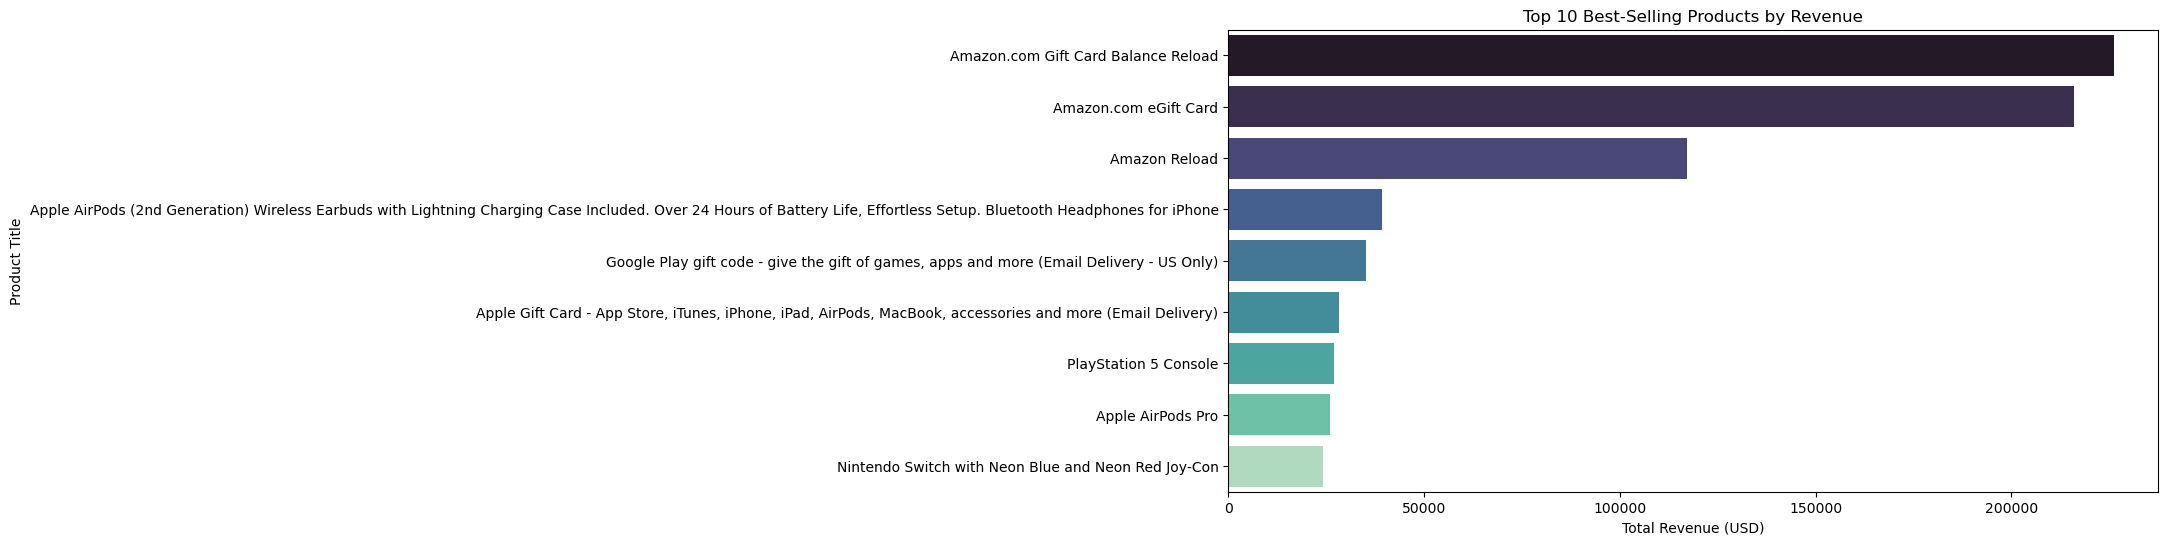

In [90]:
from pyspark.sql.functions import sum as spark_sum
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure TotalAmount is defined
cleaned_data = cleaned_data.withColumn("TotalAmount", col("Purchase Price Per Unit") * col("Quantity"))

# 2. Group by product title and sum revenue
product_revenue = cleaned_data.groupBy("Title").agg(
    spark_sum("TotalAmount").alias("Total_Revenue")
)

# 3. Get top 10 products by revenue
top_products = product_revenue.orderBy(col("Total_Revenue").desc()).limit(10)

# 4. Convert to Pandas for visualization
top_products_pd = top_products.toPandas()

# 5. Plot
plt.figure(figsize=(12, 6))
sns.barplot(data=top_products_pd, x="Total_Revenue", y="Title", palette="mako")
plt.title("Top 10 Best-Selling Products by Revenue")
plt.xlabel("Total Revenue (USD)")
plt.ylabel("Product Title")
plt.tight_layout()
plt.show()


### 4.2.3 State-wise revenue Distribution <font color = red>[5 marks]</font> <br>

Assess state-wise revenue to focus on high-growth areas

/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/3619002763.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=state_revenue_pd.head(15), x="Shipping Address State", y="Total_Revenue", palette="cubehelix")


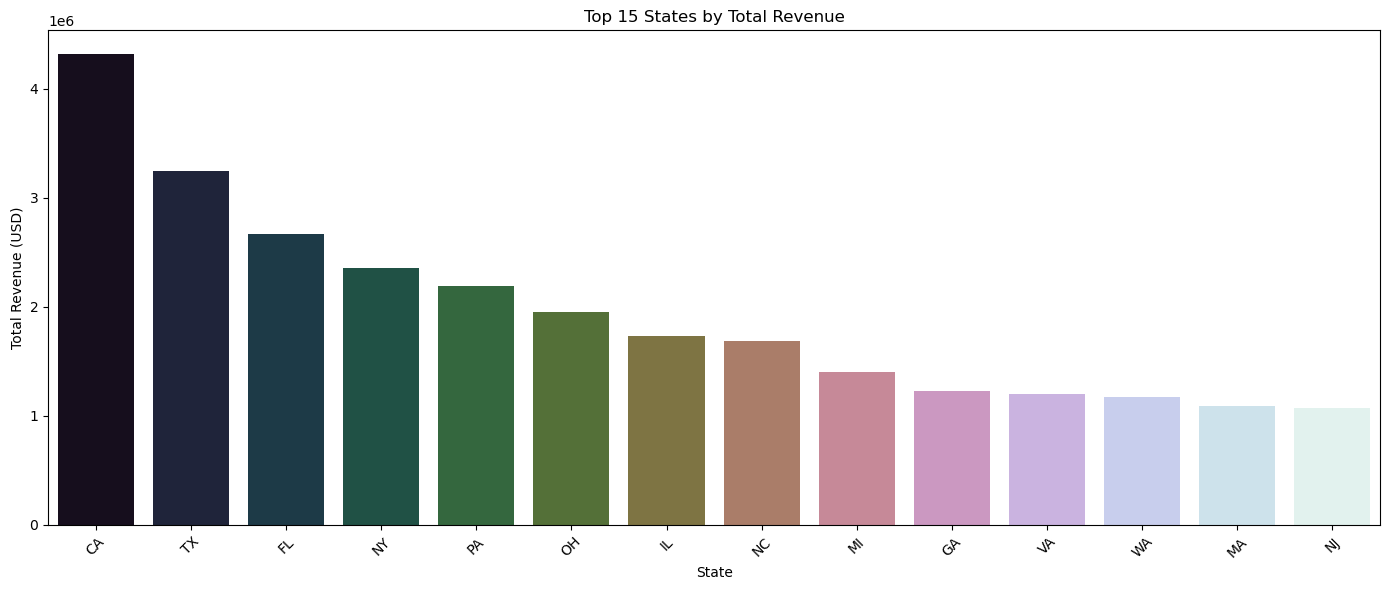

In [93]:
from pyspark.sql.functions import sum as spark_sum
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure TotalAmount column exists
cleaned_data = cleaned_data.withColumn("TotalAmount", col("Purchase Price Per Unit") * col("Quantity"))

# 2. Group by shipping state and sum revenue
state_revenue = cleaned_data.groupBy("Shipping Address State") \
    .agg(spark_sum("TotalAmount").alias("Total_Revenue"))

# 3. Convert to Pandas
state_revenue_pd = state_revenue.toPandas().sort_values("Total_Revenue", ascending=False)

# 4. Plot
plt.figure(figsize=(14, 6))
sns.barplot(data=state_revenue_pd.head(15), x="Shipping Address State", y="Total_Revenue", palette="cubehelix")
plt.title("Top 15 States by Total Revenue")
plt.xlabel("State")
plt.ylabel("Total Revenue (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 4.2.4 Repeat Purchase Behavior <font color = red>[5 marks]</font> <br>

Examine repeat purchase behavior to enhance retention initiatives.

In [97]:
from pyspark.sql.functions import count, col

# 1. Count total purchases per customer
purchase_counts = cleaned_data.groupBy("Survey ResponseID") \
    .agg(count("*").alias("Total_Purchases"))

# 2. Filter for repeat customers (more than one purchase)
repeat_customers = purchase_counts.filter(col("Total_Purchases") > 1)

# 3. Show sample of repeat customers
repeat_customers.show(10, truncate=False)

#

+-----------------+---------------+
|Survey ResponseID|Total_Purchases|
+-----------------+---------------+
|R_10TV1zyi4yCEEkl|1124           |
|R_1QgWXnlpERvWjrY|89             |
|R_1LBvKYfg8hgoloJ|7              |
|R_1mxX9jjBSLwxiDU|248            |
|R_297dOANqCntVXou|588            |
|Easter           |7              |
|R_1CqGMkfiCiATbn4|183            |
|R_1N52McSjcCnVqIm|11             |
|R_1eWdieBjoYJXAYv|965            |
|R_1esG9Jlh9NISLaO|368            |
+-----------------+---------------+
only showing top 10 rows



### 4.2.5 Flagging Potential Fraud <font color = red>[5 marks]</font> <br>

Identify irregular transaction patterns to flag potential fraud.

In [107]:
from pyspark.sql.functions import col, avg, stddev

# 1. Ensure TotalAmount column exists
cleaned_data = cleaned_data.withColumn("TotalAmount", col("Purchase Price Per Unit") * col("Quantity"))

# 2. Calculate average and standard deviation of total transaction amount
stats = cleaned_data.select(avg("TotalAmount").alias("mean_val"),
                            stddev("TotalAmount").alias("std_val")).collect()[0]

mean_val = stats["mean_val"]
std_val = stats["std_val"]

# 3. Set fraud threshold (mean + 3 * stddev)
threshold = mean_val + 3 * std_val
print(f"Fraud Threshold: {__builtins__.round(threshold, 2)} USD")


# 4. Filter transactions above the threshold
suspicious_transactions = cleaned_data.filter(col("TotalAmount") > threshold)

# 5. Show suspicious records
suspicious_transactions.select(
    "Survey ResponseID", "Order Date", "Title", "Quantity", "Purchase Price Per Unit", "TotalAmount"
).show(10, truncate=False)


Fraud Threshold: 171.7 USD
+-----------------+----------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+--------+-----------------------+-----------+
|Survey ResponseID|Order Date|Title                                                                                                                                                                                                   |Quantity|Purchase Price Per Unit|TotalAmount|
+-----------------+----------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+--------+-----------------------+-----------+
|R_0BWkZUjRId7FDZn|2018-03-05|Optoma S341 3500 Lumens SVGA 3D DLP Projector with Superior Lamp Life and HDMI                                  

### 4.2.6 Demand Variations across product categories <font color = red>[5 marks]</font> <br>

Perform inventory management by monitoring demand variations across product categories.

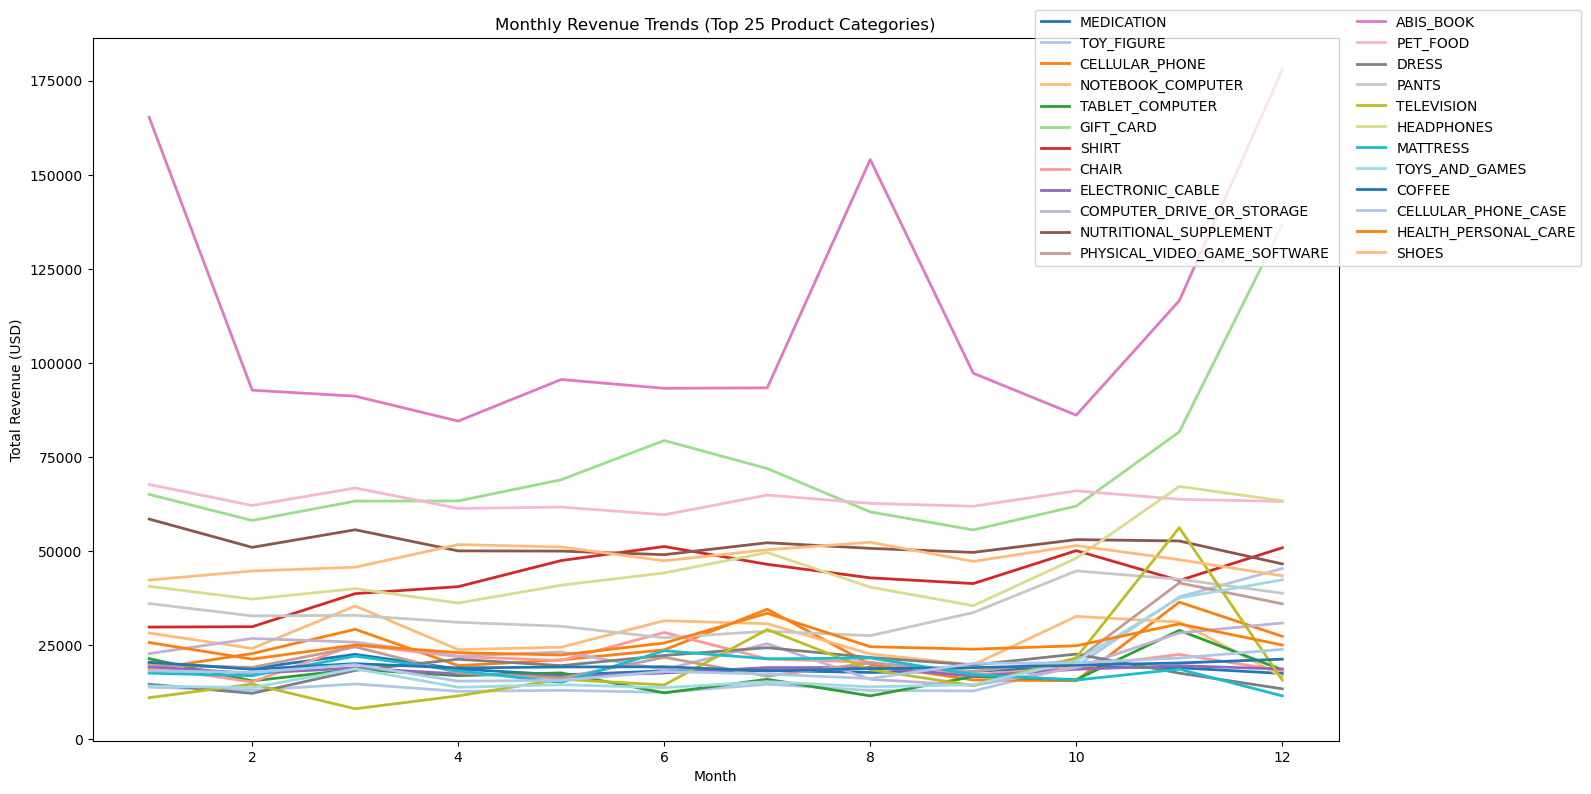

In [109]:
from pyspark.sql.functions import col, sum as spark_sum, month
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure TotalAmount exists
cleaned_data = cleaned_data.withColumn("TotalAmount", col("Purchase Price Per Unit") * col("Quantity"))

# 2. Extract month
monthly_data = cleaned_data.withColumn("Month", month(col("Order Date")))

# 3. Group by category and month, summing total revenue
category_trends = monthly_data.groupBy("Category", "Month") \
    .agg(spark_sum("TotalAmount").alias("Total_Revenue"))

# 4. Compute total revenue per category (across all months)
category_total = category_trends.groupBy("Category") \
    .agg(spark_sum("Total_Revenue").alias("Category_Revenue"))

# 5. Get top 25 categories by overall revenue
top_25_categories = category_total.orderBy(col("Category_Revenue").desc()).limit(25)
top_25_list = [row["Category"] for row in top_25_categories.collect()]

# 6. Filter main trend data to include only top 25
filtered_trends = category_trends.filter(col("Category").isin(top_25_list))

# 7. Convert to Pandas
category_trends_pd = filtered_trends.toPandas()

# 8. Plot: Line plot showing monthly trend per category
plt.figure(figsize=(16, 8))
sns.lineplot(
    data=category_trends_pd,
    x="Month",
    y="Total_Revenue",
    hue="Category",
    palette="tab20",
    linewidth=2
)
plt.title("Monthly Revenue Trends (Top 25 Product Categories)")
plt.xlabel("Month")
plt.ylabel("Total Revenue (USD)")
plt.legend(loc="upper right", bbox_to_anchor=(1.2, 1.05), ncol=2)
plt.tight_layout()
plt.show()


### 4.2.7 Assess how bulk purchases affect revenue and supply chain operations <font color = red>[5 marks]</font> <br>

Analyse the impact of how bulk purchasing behavior affects revenue and the overall supply chain operations.

/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/2605151418.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


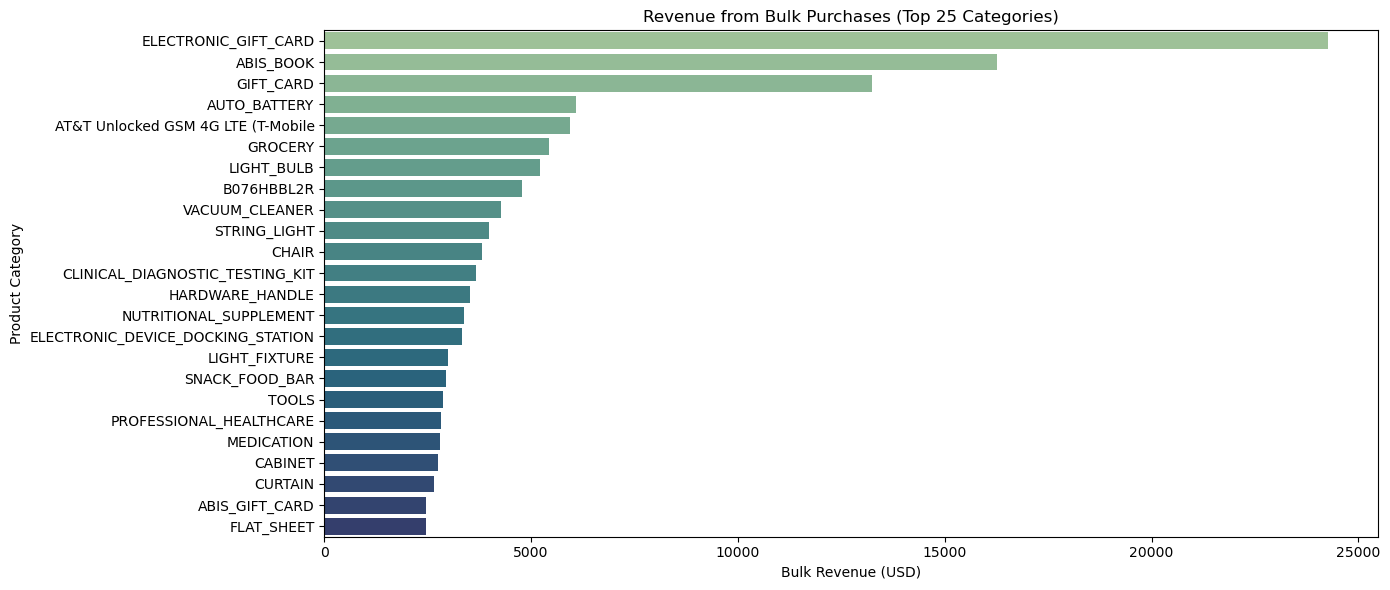

In [111]:
from pyspark.sql.functions import col, sum as spark_sum
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure TotalAmount column exists
cleaned_data = cleaned_data.withColumn("TotalAmount", col("Purchase Price Per Unit") * col("Quantity"))

# 2. Filter for bulk purchases (Quantity > 5)
bulk_purchases = cleaned_data.filter(col("Quantity") > 5)

# 3. Group by category and sum revenue
bulk_category_revenue = bulk_purchases.groupBy("Category") \
    .agg(spark_sum("TotalAmount").alias("Bulk_Revenue"))

# 4. Get top 25 categories by bulk revenue
top_bulk_categories = bulk_category_revenue.orderBy(col("Bulk_Revenue").desc()).limit(25)

# 5. Convert to Pandas
bulk_category_pd = top_bulk_categories.toPandas()

# 6. Plot
plt.figure(figsize=(14, 6))
sns.barplot(
    data=bulk_category_pd,
    y="Category",
    x="Bulk_Revenue",
    palette="crest"
)
plt.title("Revenue from Bulk Purchases (Top 25 Categories)")
plt.xlabel("Bulk Revenue (USD)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


### 4.2.8 Compare lifecycle strategies <font color = red>[5 marks]</font> <br>

Compare new and established products to inform and compare lifecycle strategies to make informed decisions.

/var/folders/9h/lxq8wqzd2p984x0j7xsb8w2c0000gn/T/ipykernel_25943/746586144.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=launch_revenue_pd, x="Launch_Year", y="Total_Revenue", palette="Set2")


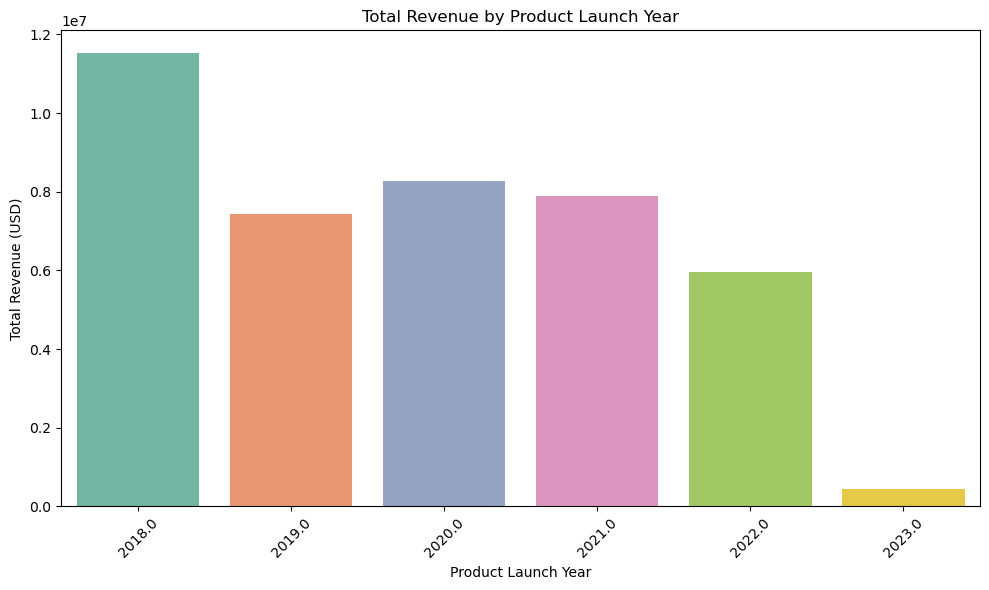

In [113]:
from pyspark.sql.functions import year, min as spark_min, sum as spark_sum, col
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract year from 'Order Date'
cleaned_data = cleaned_data.withColumn("Order_Year", year(col("Order Date")))

# 2. Get Launch Year: First sale year for each product
product_launch = cleaned_data.groupBy("Title").agg(
    spark_min("Order_Year").alias("Launch_Year")
)

# 3. Join back to cleaned_data to associate each transaction with product launch year
data_with_launch = cleaned_data.join(product_launch, on="Title", how="left")

# 4. Compute revenue by launch year
launch_revenue = data_with_launch.groupBy("Launch_Year") \
    .agg(spark_sum("TotalAmount").alias("Total_Revenue")) \
    .orderBy("Launch_Year")

# 5. Convert to Pandas
launch_revenue_pd = launch_revenue.toPandas()

# 6. Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=launch_revenue_pd, x="Launch_Year", y="Total_Revenue", palette="Set2")
plt.title("Total Revenue by Product Launch Year")
plt.xlabel("Product Launch Year")
plt.ylabel("Total Revenue (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#5 Conclusion <font color = red>[10 marks]</font> <br>

Write your conclusion.

In [116]:
#In this project, we utilized Apache Spark to perform a detailed behavioral and transactional analysis of customers in a large-scale e-commerce environment. By integrating transactional, demographic, and survey datasets, we were able to uncover meaningful patterns that support data-driven business decision-making.

#The customer segmentation using RFM (Recency, Frequency, Monetary) analysis enabled us to categorize users based on their engagement and value. This segmentation forms the foundation for personalized marketing campaigns, allowing the business to target high-value, frequent, or at-risk customers with tailored messaging and promotions.

#Our promotional timing analysis revealed that purchases tend to peak midweek, particularly on Wednesdays and Thursdays. This insight can be leveraged to schedule campaigns and discounts when customer engagement is naturally higher, maximizing conversion rates. Furthermore, the top-selling products and high-revenue regions such as California and Texas provide direction for optimizing marketing spend and inventory allocation.

#In terms of inventory management, monthly revenue trends across the top 25 categories showcased clear seasonal variations in demand. Analyzing bulk purchases (orders with large quantities) further helped identify categories that require proactive inventory planning due to high-volume orders. These findings can be used to adjust supply chain operations and maintain stock levels efficiently.

#We also identified potential instances of fraudulent activity by flagging transactions with spending far above average thresholds. This not only adds a layer of operational security but also highlights customers who might be engaged in wholesale or irregular purchasing behaviors. Additionally, a comparison between new and established products based on launch years revealed how newer entries perform in the market and when product life cycle strategies like renewal or phase-out should be considered.

#Overall, the analysis presents several actionable insights. Businesses can optimize stock levels in alignment with seasonal and category-specific trends, enhance customer retention through targeted engagement strategies, and ensure pricing strategies reflect customer segmentation. Lastly, high-performing regions can be prioritized for marketing campaigns, ensuring both budget efficiency and revenue growth.